In [ ]:
%load_ext autoreload
%autoreload 2

### Figure 4: Assay-specific updating with PepCL.

 - __a)__ YD and matched MS updating results.
 - __b)__ YD/MS trade-off for PepCL and FT.
 - __c)__ YD/MS uniform mixture analysis.
 - __d)__ EpiScan sets log odds derived from MS train binders.
 - __e)__ EpiScan updating results.
 - __f)__ BA updating results.
 - __g)__ ESCAPE-seq tumor neoantigen rank and recovery.
 - __h)__ ESCAPE-seq differential mutation scoring results.

In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT.name != "PepCL_Manuscript":
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("Could not find PepCL_Manuscript project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "Data"
SRC_DIR = PROJECT_ROOT / "src"
FIGURES_DIR = PROJECT_ROOT / "Figures"
MODEL_CHECKPOINTS_DIR = PROJECT_ROOT / "Model_Checkpoints"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("PROJECT_ROOT in sys.path:", str(PROJECT_ROOT) in sys.path)

PROJECT_ROOT: /home/pchati/PepCL_Manuscript
PROJECT_ROOT in sys.path: True


In [ ]:
# get mhc pseudosequences
from Data.mhc_pseudo_seqs import mhc_seq_dict
mhc_seq_dict={k.removeprefix("HLA-").replace("*","").replace(":",""):v for k,v in mhc_seq_dict.items()}

# get utils
from src.general_utils import *

# get feature data and processed feature table
from src.get_feature_data import *

# plotting fns
from src.plotting import *

# misc
import warnings
warnings.filterwarnings("ignore")
device="cuda"

In [ ]:
"""
Set figure output directory
"""
# create central repository and for this figure
central_figure_dir="Figure4"

# associated data dir
associated_data_dir=f"{central_figure_dir}/Associated_Data"

### Fig. 4a: YD and matched MS updating results

In [ ]:
# yd/ms test sets and nmp41 ba run
holec_datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "Holec_et_al_2025"
holec_test_set  = pd.read_csv(f"{holec_datasets_dir}/holec_test_set.csv", index_col=0)
holec_test_set_with_benchmarking_model_scores  = pd.read_csv(f"{holec_datasets_dir}/holec_test_set_with_benchmarking_model_scores.csv", index_col=0)

datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets"
ms_test_data=pd.read_csv(f"{datasets_dir}/ms_test_data.csv", index_col=0)
ms_test_data_with_benchmarking_model_scores=pd.read_csv(f"{datasets_dir}/ms_test_data_with_benchmarking_model_scores.csv", index_col=0)

In [ ]:
# process and extract ba info
ms_test_data=full_process_data(ms_test_data, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
ms_test_data=create_seq_allele_column(ms_test_data)

ms_test_data_with_benchmarking_model_scores=full_process_data(ms_test_data_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
ms_test_data_with_benchmarking_model_scores=create_seq_allele_column(ms_test_data_with_benchmarking_model_scores)

holec_test_set=full_process_data(holec_test_set, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
holec_test_set=create_seq_allele_column(holec_test_set)

holec_test_set_with_benchmarking_model_scores=full_process_data(holec_test_set_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
holec_test_set_with_benchmarking_model_scores=create_seq_allele_column(holec_test_set_with_benchmarking_model_scores)

seq_allele_to_ba_score=dict(zip(ms_test_data_with_benchmarking_model_scores.seq_allele, ms_test_data_with_benchmarking_model_scores.BA_score))
ms_test_data["BA_score"]=ms_test_data.seq_allele.map(seq_allele_to_ba_score)

seq_allele_to_ba_score=dict(zip(holec_test_set_with_benchmarking_model_scores.seq_allele, holec_test_set_with_benchmarking_model_scores.BA_score))
holec_test_set["BA_score"]=holec_test_set.seq_allele.map(seq_allele_to_ba_score)

In [ ]:
# ap per allele
# get ap matrix
score_cols=["mhcprime", "holec_ft", "holec_pepcl"]
score_cols+=["BA_score"]

# ms test set (matched allele-length distribution)
ms_test_data["seq_len"]=ms_test_data.seq.str.replace("$", "").apply(len)
ms_allele_ap_df=compute_ap_matrix_optimized(ms_test_data[ms_test_data.allele.isin(holec_test_set.allele.unique().tolist())].query("seq_len == 9"), score_cols, label_col='label', allele_col='allele', disable_tqdm=True)

# holec test set
holec_allele_ap_df=compute_ap_matrix_optimized(holec_test_set, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)

In [ ]:
"""
Plotting parameters for boxplots.
"""
score_cols=["mhcprime", "holec_ft", "holec_pepcl"]

model_groups = {
    'MHCPrime': ["mhcprime"],
    'FT': ["holec_ft"],
    'PepCL': ["holec_pepcl"],
}

x_ticks = ['']
print(model_groups)

colors = {
    'MHCPrime': '#081470',
    'FT': '#bababa',
    'PepCL': '#9bb0ed',
}

plot_params = {
    'title': '',
    'title_y': 1.04,
    'title_bbox': None,

    # 'title_fontsize': 7,
    'title_fontsize': 6,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AP',
    # 'xlabel_fontsize': 7,
    # 'ylabel_fontsize': 7,
    'xlabel_fontsize': 6,
    'ylabel_fontsize': 6,
    'figsize': (1.20, 1.65),
    'dpi': 300,
    'legend_fontsize': 6,
    'legend_cols': 3,
    'legend_handle_size': 0.7,
    'axis_linewidth': 0.35,
    # 'axis_linewidth': 0.30,
    # 'axis_linewidth': 0.25,
    'tick_length': 2.2,
    'xlabel_pad': 1,
    'ylabel_pad': 1.5,
    'xtick_labelsize': 5.5,
    'ytick_labelsize': 6,
}

plotting_parameters = dict(
    model_col='model_name',
    score_col='metric',
    model_groups=model_groups,
    x_ticks=[''],
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 1.0),
    grid_alpha=0,
    default_font='Nimbus Sans',
    mode='box',
    bar_width=0.32,
    bar_spacing=0.08,
    group_spacing=0.10,
    x_margin=0.12,
    bar_outline_color='black',
    box_median_width=0.60,
    # bar_outline_width=0.35,
    # box_whisker_width=0.30,
    bar_outline_width=0.40,
    box_whisker_width=0.40,
    box_flier_size=0,
    legend_mode=None,
    xtick_rotation=0,
    pval_df=None,
    pval_fontsize=4,
    pval_linewidth=0.35,
    pval_color='black',
    pval_bar_offset=0.035,
    pval_bar_spacing=0.06,
    pval_text_offset=0.004,
    pval_star_text_offset=-0.01,
    pval_ns_text_offset=0.004,
)

{'MHCPrime': ['mhcprime'], 'FT': ['holec_ft'], 'PepCL': ['holec_pepcl']}


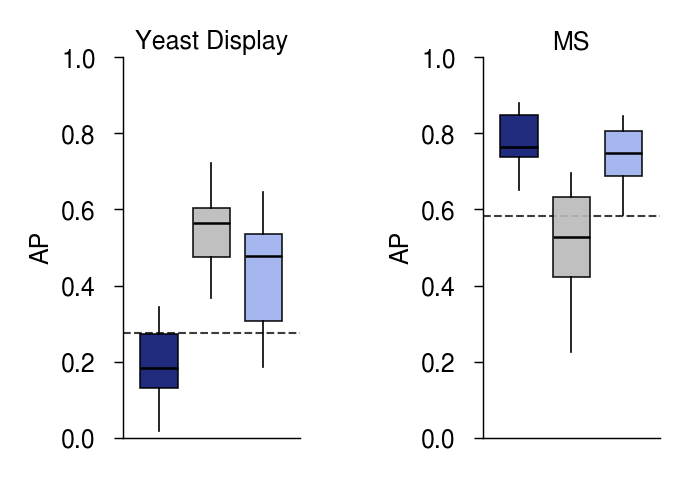

In [ ]:
# plot all together
plot_dict = {
    'yeast_display': {
        'title': 'Yeast Display',
        'df': holec_allele_ap_df,
    },
    'ms_for_yeast': {
        'title': 'MS',
        'df': ms_allele_ap_df,
    },
}

fig, axes = plot_model_performance_box_grid_v2(
    plot_dict=plot_dict,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_a_yd_ms_updating_per_allele_ap_boxplots",
    panel_gap=0.00,
    grid_dpi=300,
    reference_hlines={
        'BA_score': {
            'color': "#3c3c3c", 'linestyle': '--', 'linewidth': 0.5,
            'label': 'BA score (100%)', 
            'agg': 'median',   
        }, # 'alpha': 0.8,
    },
    **plotting_parameters,
)


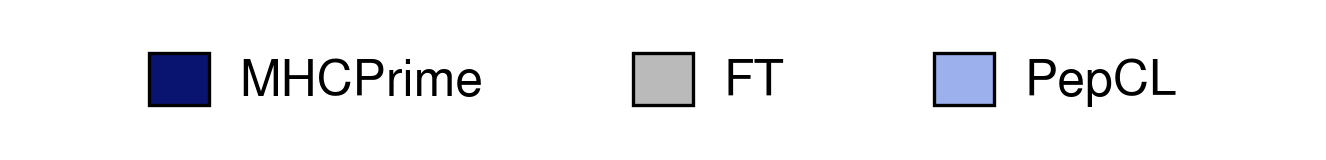

In [ ]:
# legend resized and formatted in illustrator (BA score median line added to legend in illustrator)
plot_horizontal_legend(
    legend_dict={
        'MHCPrime': '#081470',
        'FT': '#bababa',
        'PepCL': '#9bb0ed',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_a_legend",
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    # ap dfs
    ms_allele_ap_df.to_csv(f"{associated_data_dir}/ms_allele_ap_df.csv")
    holec_allele_ap_df.to_csv(f"{associated_data_dir}/holec_allele_ap_df.csv")

### Fig. 4b: YD/MS trade-off for PepCL and FT

In [ ]:
# get trade-off dfs
ft_tradeoff_df = compute_net_adaptation_benefit(
    ms_df=ms_allele_ap_df,
    holec_df=holec_allele_ap_df,
    base_col="mhcprime",
    score_col="holec_ft",
    output_col="ft_net_benefit"
)

pepcl_tradeoff_df = compute_net_adaptation_benefit(
    ms_df=ms_allele_ap_df,
    holec_df=holec_allele_ap_df,
    base_col="mhcprime",
    score_col="holec_pepcl",
    output_col="pepcl_net_benefit"
)

# merge
ft_pepcl_tradeoff_df=pd.concat([ft_tradeoff_df, pepcl_tradeoff_df], axis=1)

# sort potentially
ft_pepcl_tradeoff_df.sort_values(by="pepcl_net_benefit", ascending=False, inplace=True)

# reformat alleles
def format_allele_index(df):
    def convert(a):
        return f"{a[0]}*{a[1:3]}:{a[3:]}"
    df.index = df.index.map(convert)
    return df

ft_pepcl_tradeoff_df=format_allele_index(ft_pepcl_tradeoff_df)

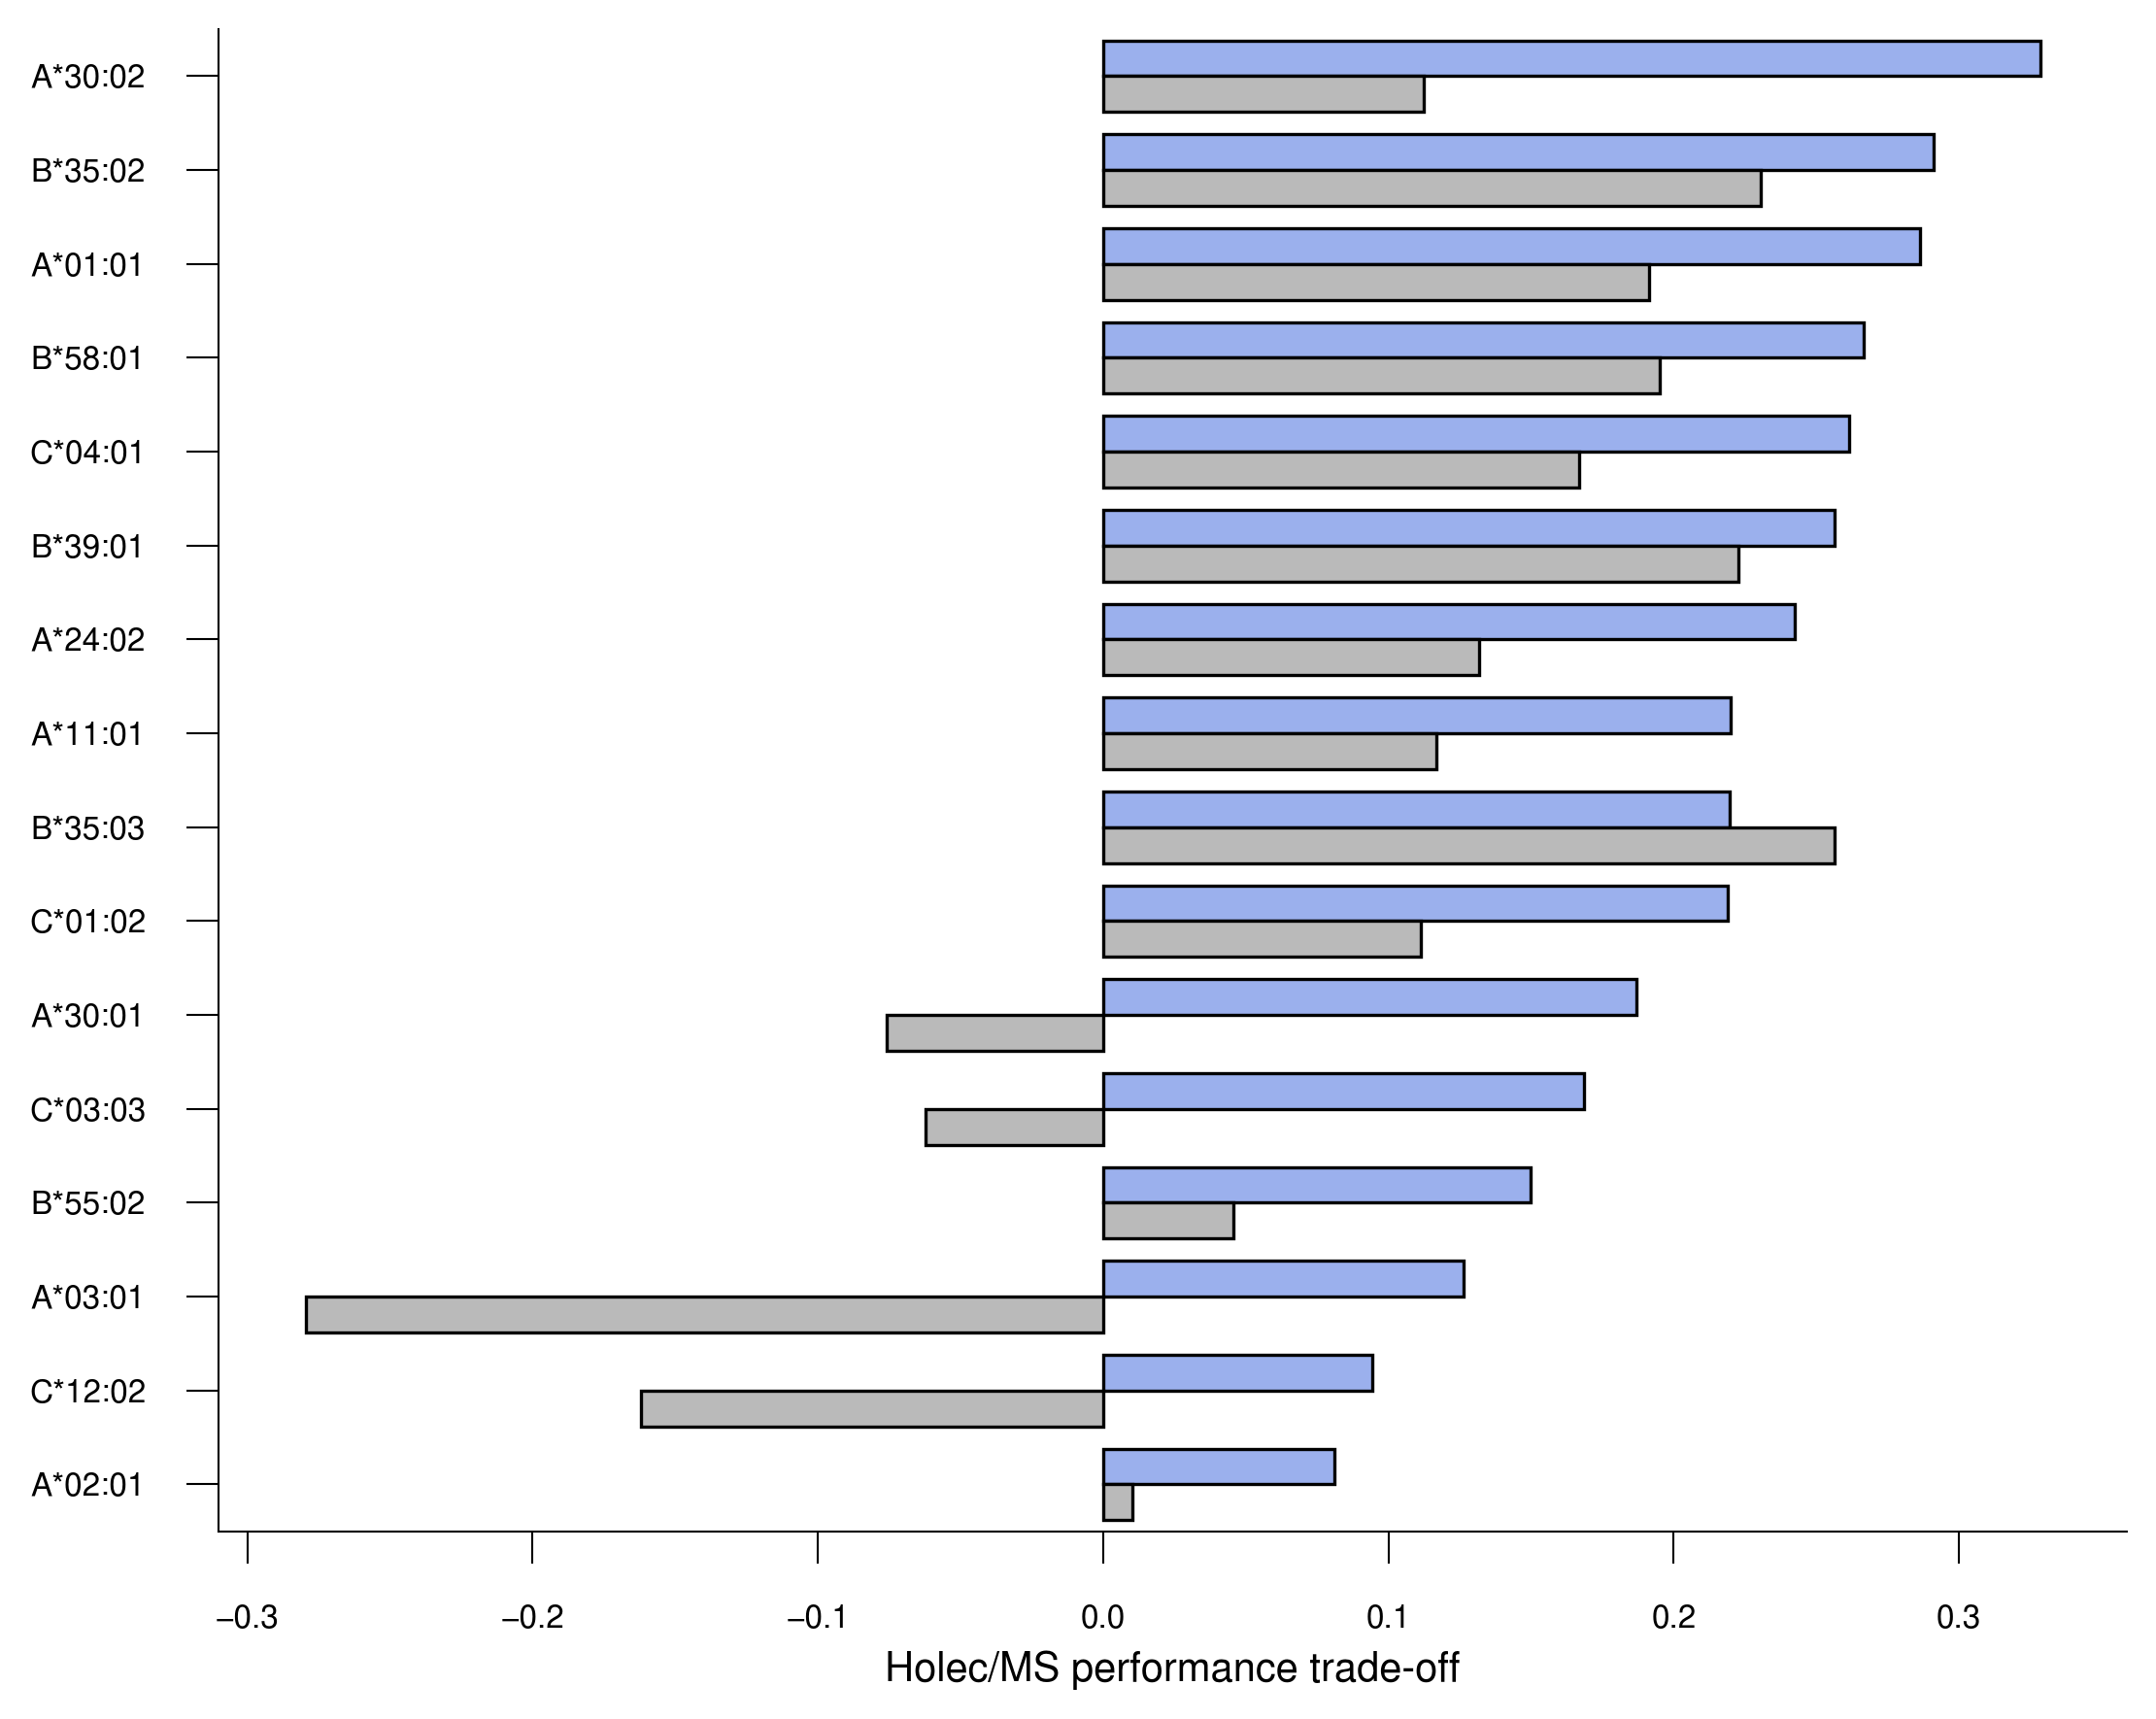

In [ ]:
"""
Plot trade-off DF.
"""
plot_bar_grouped_advanced(
    ft_pepcl_tradeoff_df,
    ["pepcl_net_benefit", "ft_net_benefit"],
    figsize=(7.5, 6),
    dpi=300,
    default_font='Nimbus Sans',
    bar_width=0.8,
    bar_edgecolor='black',
    bar_edgewidth=0.8,
    alpha=1.0,
    group_spacing=0.5,
    colors=["#9bb0ed", "#bababa"],
    # horizontal=False,
    horizontal=True,
    xlabel='Holec/MS performance trade-off',
    ylabel="",
    xlabel_fontsize=10,
    ylabel_fontsize=10,
    xlabel_pad=4.0,
    ylabel_pad=4.0,
    title='',
    title_fontsize=12,
    title_bold=True,
    xtick_labelsize=8,
    ytick_labelsize=8,
    tick_length=8.0,
    tick_width=0.5,
    tick_direction='out',
    rotation=0,
    axis_linewidth=0.5,
    ylim=None,
    xlim=None,
    grid_alpha=0.0,
    legend_mode='none',
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_b_yd_ms_trade_off_barplot",
)


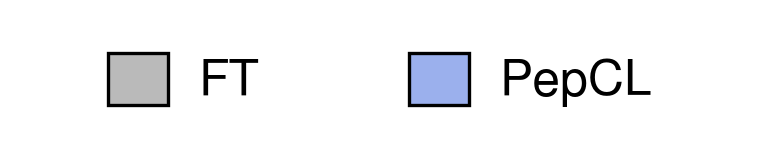

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'FT': '#bababa',
        'PepCL': '#9bb0ed',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_b_legend",
)

In [ ]:
# compute p-values
tradeoff_pval_df=compute_pairwise_pvalues_general(ft_pepcl_tradeoff_df)

display(tradeoff_pval_df)
display(pval_to_stars(tradeoff_pval_df))

,ft_net_benefit,pepcl_net_benefit
ft_net_benefit,1.000000,0.000092
pepcl_net_benefit,0.000092,1.000000


,ft_net_benefit,pepcl_net_benefit
ft_net_benefit,ns,****
pepcl_net_benefit,****,ns


{'FT': ['ft_net_benefit'], 'PepCL': ['pepcl_net_benefit']}


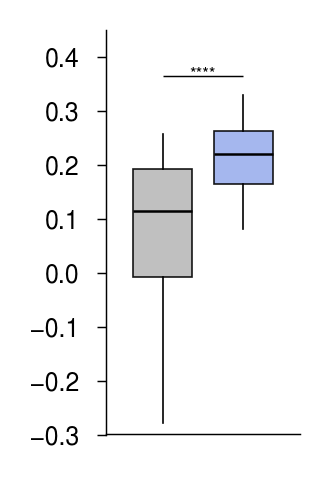

In [ ]:
"""
Trade-off inset boxplots.
"""
score_cols=["ft_net_benefit", "pepcl_net_benefit"]

model_groups = {
    'FT': ["ft_net_benefit"],
    'PepCL': ["pepcl_net_benefit"],
}

x_ticks = ['']
print(model_groups)

colors = {
    'FT': '#bababa',
    'PepCL': '#9bb0ed',
}

plot_params = {
    'title': '',
    'title_y': 1.04,
    'title_bbox': None,

    # 'title_fontsize': 7,
    'title_fontsize': 6,
    'title_bold': False,
    'xlabel': '',
    'ylabel': '',
    # 'xlabel_fontsize': 7,
    # 'ylabel_fontsize': 7,
    'xlabel_fontsize': 6,
    'ylabel_fontsize': 6,
    'figsize': (1.20, 1.65),
    'dpi': 300,
    'legend_fontsize': 6,
    'legend_cols': 3,
    'legend_handle_size': 0.7,
    'axis_linewidth': 0.35,
    # 'axis_linewidth': 0.30,
    # 'axis_linewidth': 0.25,
    'tick_length': 2.2,
    'xlabel_pad': 1,
    'ylabel_pad': 1.5,
    'xtick_labelsize': 5.5,
    'ytick_labelsize': 6,
}

plotting_parameters = dict(
    model_col='model_name',
    score_col='metric',
    model_groups=model_groups,
    x_ticks=[''],
    colors=colors,
    plot_params=plot_params,
    ylim=(-0.3, 0.45),
    grid_alpha=0,
    default_font='Nimbus Sans',
    mode='box',
    bar_width=0.32,
    bar_spacing=0.08,
    group_spacing=0.10,
    x_margin=0.12,
    bar_outline_color='black',
    box_median_width=0.60,
    # bar_outline_width=0.35,
    # box_whisker_width=0.30,
    bar_outline_width=0.40,
    box_whisker_width=0.40,
    box_flier_size=0,
    legend_mode=None,
    xtick_rotation=0,

    pval_df=None,
    pval_fontsize=4,
    pval_linewidth=0.35,
    pval_color='black',
    pval_bar_offset=0.035,
    pval_bar_spacing=0.06,
    pval_text_offset=0.004,
    pval_star_text_offset=-0.01,
    pval_ns_text_offset=0.004,
)

plotting_parameters["pval_df"]=tradeoff_pval_df
_=plot_model_performance_bars_or_box_v2(
    df=ft_pepcl_tradeoff_df,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_b_yd_ms_trade_off_inset_boxplot",
    **plotting_parameters
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    # trade off and pval dfs
    ft_pepcl_tradeoff_df.to_csv(f"{associated_data_dir}/ft_pepcl_tradeoff_df.csv")
    tradeoff_pval_df.to_csv(f"{associated_data_dir}/tradeoff_pval_df.csv")

### Fig. 4c: YD/MS uniform mixture analysis

In [ ]:
%%time
"""
Mixture analysis
"""
base_score_col="mhcprime"
score_cols_temp=["holec_ft", "holec_pepcl"]

delta_mean_df, delta_var_df, delta_ci_df = compute_mixed_ms_holec_map_bootstrap_delta_from_base(
    ms_df=ms_test_data[ms_test_data.allele.isin(holec_test_set.allele.unique().tolist())].query("seq_len == 9"), # isolate to alleles
    holec_df=holec_test_set,
    base_col=base_score_col,
    score_cols=score_cols_temp,
    allele_col="allele",
    ms_label_col = "label",
    holec_label_col = "label",
    neg_per_pos_ratio=99,
    mix_step_pct=10.0,
    n_iterations=100,
    ci_alpha=0.95,
    random_state=42,
    show_progress=True,
)

Mixing steps: 100%|██████████| 11/11 [00:36<00:00,  3.36s/it]

CPU times: user 37.6 s, sys: 372 ms, total: 38 s
Wall time: 37.7 s


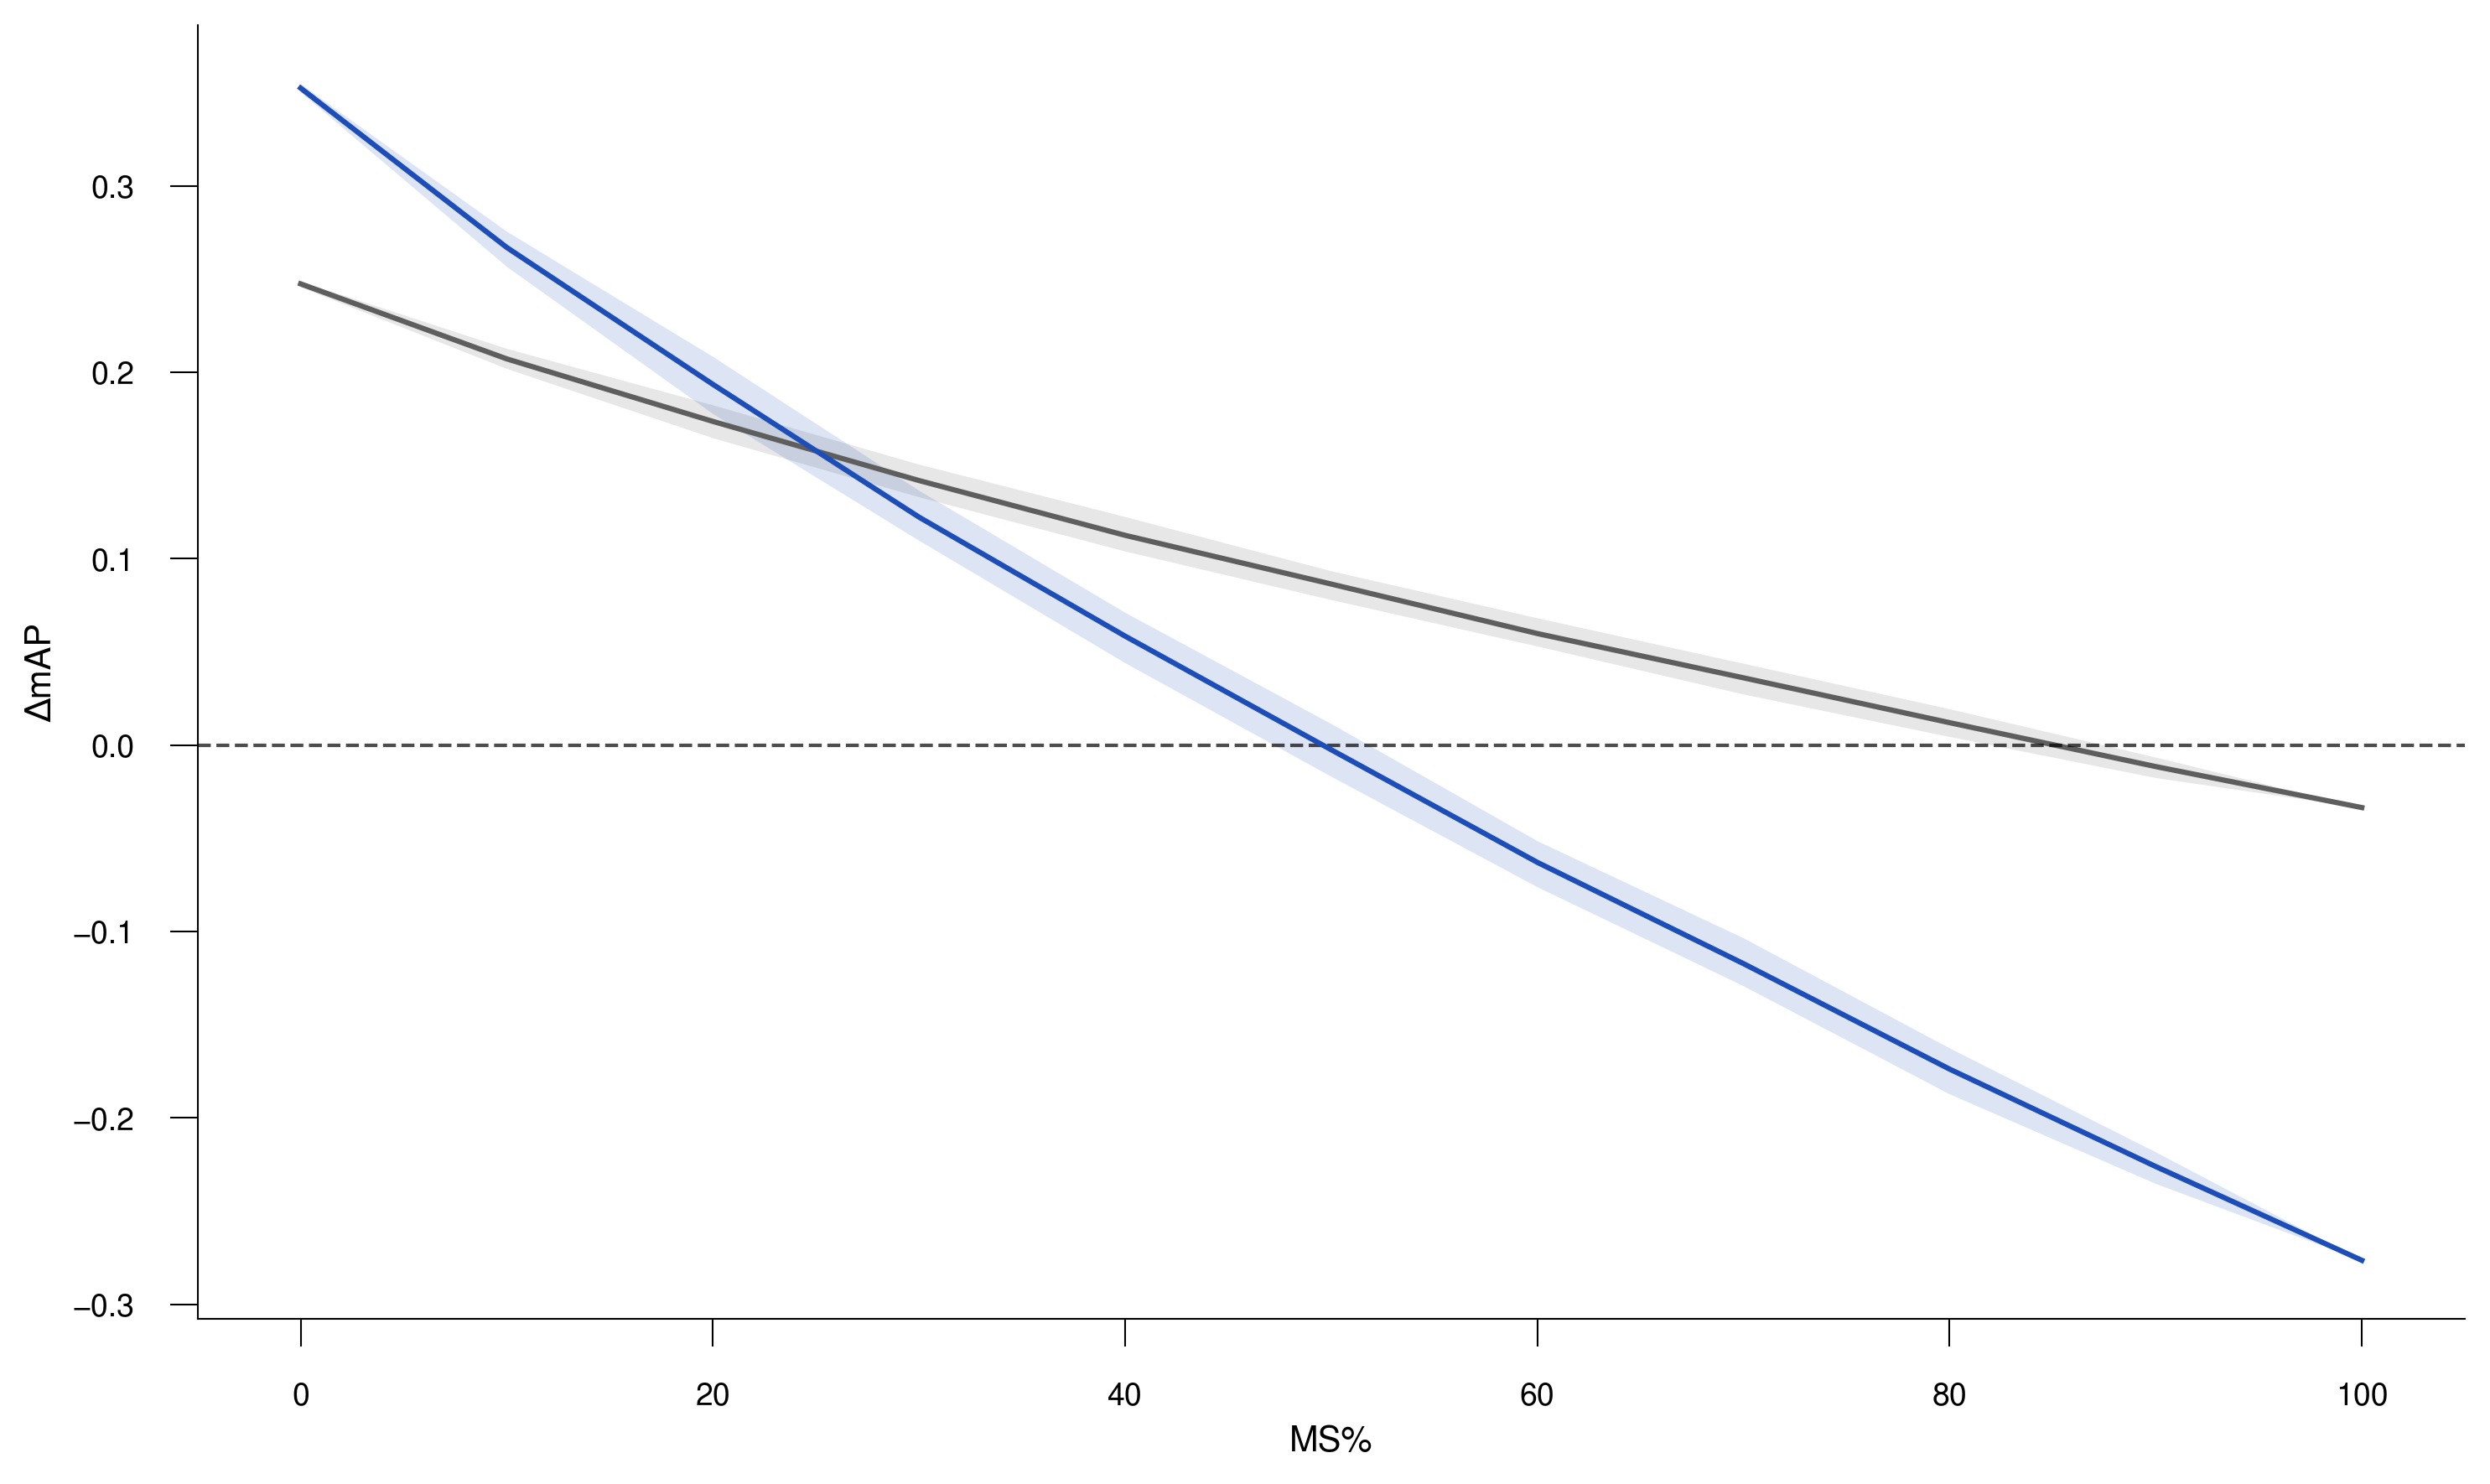

In [ ]:
# plot mixture analysis results
line_styles = {
    'holec_ft': {
        'color': '#1D4EB8',
        'linewidth': 1.5,
        'linestyle': '-',
        'marker': None,
        'alpha': 1.0,
        'zorder': 2,
        'ci_color': '#1D4EB8',
        'ci_alpha': 0.15,
    },
    'holec_pepcl': {
        'color': "#5E5E5E",
        'linewidth': 1.5,
        'linestyle': '-',
        'marker': None,
        'alpha': 1.0,
        'zorder': 1,
        'ci_color': '#5E5E5E',
        'ci_alpha': 0.15,
    },
}

plot_lines(
    delta_mean_df.reset_index(),
    x_col="ms_percentage",
    y_cols=["holec_ft", "holec_pepcl"],
    line_styles=line_styles,
    ci_df=delta_ci_df.reset_index(),
    figsize=(10, 6),
    dpi=300,
    default_font='Nimbus Sans',
    xlabel='MS%',
    ylabel='ΔmAP',
    xlabel_fontsize=10,
    ylabel_fontsize=10,
    xlabel_pad=4.0,
    ylabel_pad=4.0,
    title='',
    title_fontsize=12,
    title_bold=True,
    xtick_labelsize=9,
    ytick_labelsize=9,
    tick_length=8.0,
    tick_width=0.5,
    tick_direction='out',
    xtick_rotation=0,
    axis_linewidth=0.5,
    xlim=None,
    ylim=None,
    grid_alpha=0.0,
    legend_mode=None,
    legend_loc='upper right',
    legend_bbox=None,
    legend_ncol=1,
    legend_fontsize=9,
    legend_handle_size=1.0,
    hline_y=0.0,
    hline_color='black',
    hline_width=1.0,
    hline_style='--',
    hline_alpha=0.7,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_c_yd_ms_mixture_lineplots",

)

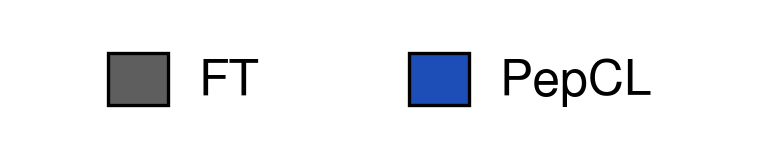

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'FT': '#5E5E5E',
        'PepCL': '#1D4EB8',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_b_legend",
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    # trade off and pval dfs
    delta_mean_df.to_csv(f"{associated_data_dir}/yd_ms_mixture_analysis_map_df.csv")
    delta_ci_df.to_csv(f"{associated_data_dir}/yd_ms_mixture_analysis_ci_df.csv")

### Fig. 4d: EpiScan sets log odds derived from MS train binders

In [ ]:
# ms and episcan test sets

# ms
datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets"
ms_test_data=pd.read_csv(f"{datasets_dir}/ms_test_data.csv", index_col=0)

# episcan
episcan_train_test_dir = DATA_DIR / "Training_Datasets" / "Processed" / "EpiScan"
episcan_r9_test_set=pd.read_csv(f"{episcan_train_test_dir}/episcan_r9_test_set.csv", index_col=0)
episcan_rt_test_set=pd.read_csv(f"{episcan_train_test_dir}/episcan_rt_test_set.csv", index_col=0)

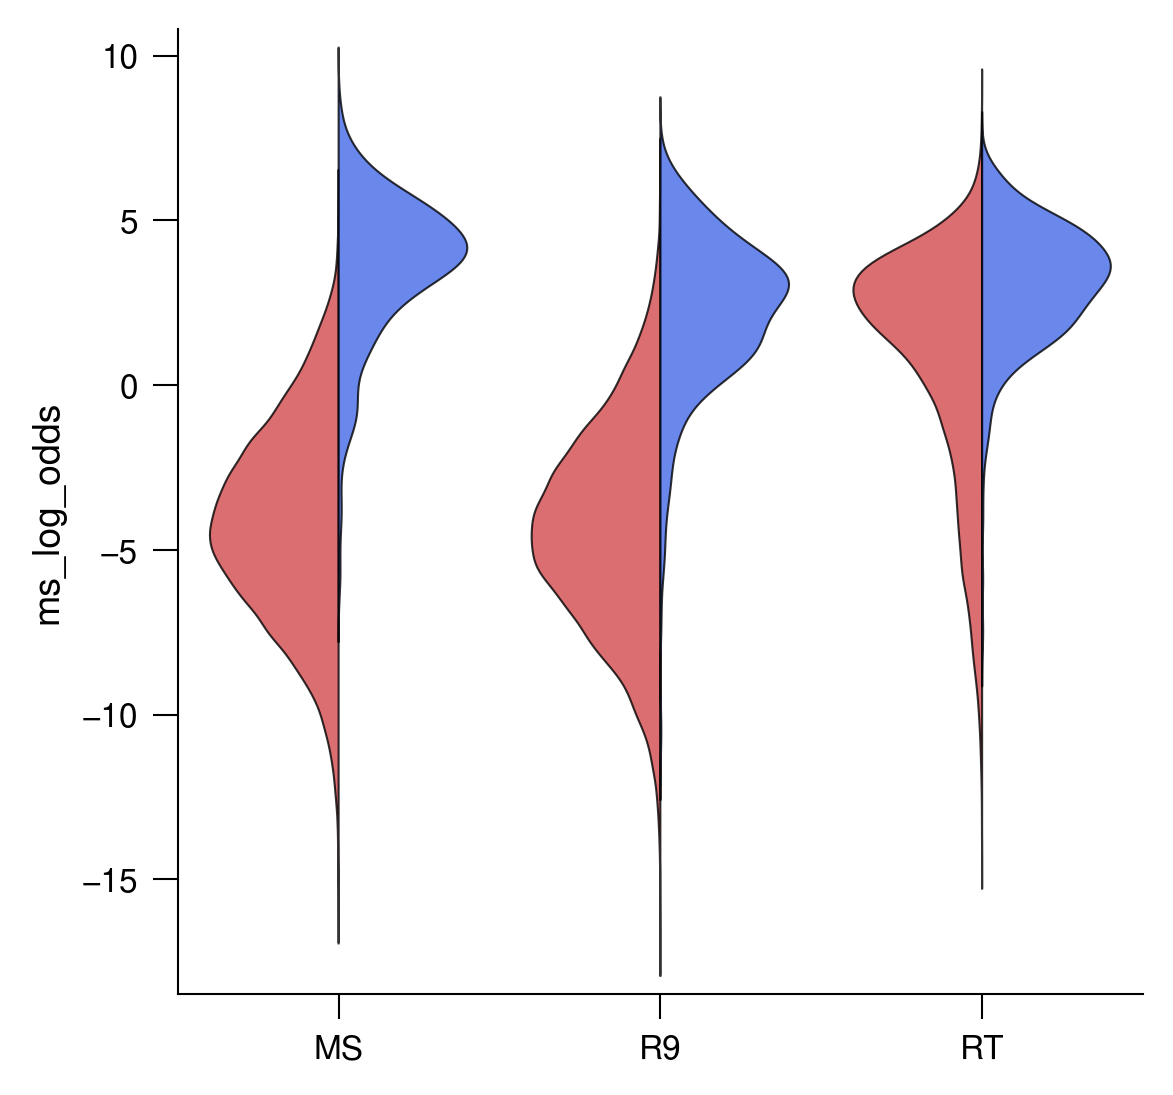

In [ ]:
# get log odds figure
ms_test_data["seq_len"]=ms_test_data.seq.str.replace("$", "").apply(len)

test_dfs={
    "MS": ms_test_data[ms_test_data.allele.isin(["A0201", "A0301", "B0801", "B5701"])].query("seq_len == 9"),
    "R9": episcan_r9_test_set,
    "RT": episcan_rt_test_set
}

plot_split_violin_grid_with_ap_modified_betweenx_updated(
    test_dfs,
    label_cols={'MS': 'label', 'R9': 'label', 'RT': 'label'},
    score_col="ms_log_odds",
    aggregate_ap='per_allele',
    neg_color="#D34A4D",
    pos_color="#456be8",
    neg_edge_color='black',
    pos_edge_color='black',
    neg_edge_width=0.5,
    pos_edge_width=0.5,
    ap_line_color='black',
    ap_marker='o',
    ap_marker_size=4,
    ap_line_width=1.0,
    figsize=(4, 4),
    dpi=300,
    suptitle=None,
    ylabel_violin=None,
    ylabel_ap='AP',
    tick_fontsize=8,
    label_fontsize=9,
    title_fontsize=10,
    suptitle_fontsize=12,
    legend_fontsize=8,
    violin_width=0.8,
    violin_alpha=0.8,
    ylim_violin=None,
    ap_ylim=(-0.05, 1.05),
    height_ratio=0.3,
    hspace=0.05,
    kde_extend=3.0,
    kde_points=200,
    spine_width_violin=0.5,
    spine_width_ap=0.5,
    tick_width_violin=0.5,
    tick_width_ap=0.5,
    tick_length_violin=6,
    tick_length_ap=6,
    ap_tick_margin=None,
    hide_ap=True, 
    hide_legend=True,
    square_aspect=True,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_d_ms_r9_rt_log_odds_distributions_from_ms_binders",
)


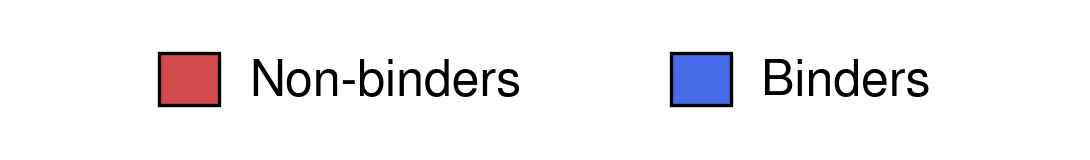

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'Non-binders': '#D34A4D',
        'Binders': '#456be8',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_d_legend",
)

In [ ]:
# get allele ap matrices
ms_allele_ap_matrix=compute_ap_matrix_optimized(ms_test_data[ms_test_data.allele.isin(["A0201", "A0301", "B0801", "B5701"])].query("seq_len == 9"), ["ms_log_odds"], label_col='label', allele_col='allele')

r9_allele_ap_matrix=compute_ap_matrix_optimized(episcan_r9_test_set, ["ms_log_odds"], label_col='label', allele_col='allele')

rt_allele_ap_matrix=compute_ap_matrix_optimized(episcan_rt_test_set, ["ms_log_odds"], label_col='label', allele_col='allele')

100%|██████████| 4/4 [00:00<00:00, 455.30it/s]


In [ ]:
# get df
ms_r9_rt_log_odds_from_ms_binders_df=pd.concat([pd.DataFrame(ms_allele_ap_matrix.mean(), columns=["MS"]), pd.DataFrame(r9_allele_ap_matrix.mean(), columns=["R9"]), pd.DataFrame(rt_allele_ap_matrix.mean(), columns=["RT"])], axis=1)
display(ms_r9_rt_log_odds_from_ms_binders_df)

,MS,R9,RT
ms_log_odds,0.724772,0.361551,0.024909


In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    ms_r9_rt_log_odds_from_ms_binders_df.to_csv(f"{associated_data_dir}/ms_r9_rt_log_odds_from_ms_binders_df.csv")

### Fig. 4e: EpiScan updating results

In [ ]:
# ms and episcan test sets

# ms
datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets"
ms_test_data=pd.read_csv(f"{datasets_dir}/ms_test_data.csv", index_col=0)
ms_test_data_with_benchmarking_model_scores=pd.read_csv(f"{datasets_dir}/ms_test_data_with_benchmarking_model_scores.csv", index_col=0)

# episcan
episcan_train_test_dir = DATA_DIR / "Training_Datasets" / "Processed" / "EpiScan"
episcan_r9_test_set=pd.read_csv(f"{episcan_train_test_dir}/episcan_r9_test_set.csv", index_col=0)
episcan_rt_test_set=pd.read_csv(f"{episcan_train_test_dir}/episcan_rt_test_set.csv", index_col=0)
sd3_formatted=pd.read_csv(f"{episcan_train_test_dir}/sd3_formatted.csv", index_col=0)

episcan_r9_test_set_with_benchmarking_model_scores=pd.read_csv(f"{episcan_train_test_dir}/episcan_r9_test_set_with_benchmarking_model_scores.csv", index_col=0)
episcan_rt_test_set_with_benchmarking_model_scores=pd.read_csv(f"{episcan_train_test_dir}/episcan_rt_test_set_with_benchmarking_model_scores.csv", index_col=0)
sd3_formatted_with_benchmarking_model_scores=pd.read_csv(f"{episcan_train_test_dir}/sd3_formatted_with_benchmarking_model_scores.csv", index_col=0)

In [ ]:
# process
ms_test_data=full_process_data(ms_test_data, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
ms_test_data=create_seq_allele_column(ms_test_data)

ms_test_data_with_benchmarking_model_scores=full_process_data(ms_test_data_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
ms_test_data_with_benchmarking_model_scores=create_seq_allele_column(ms_test_data_with_benchmarking_model_scores)

episcan_r9_test_set=full_process_data(episcan_r9_test_set, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
episcan_r9_test_set=create_seq_allele_column(episcan_r9_test_set)

episcan_rt_test_set=full_process_data(episcan_rt_test_set, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
episcan_rt_test_set=create_seq_allele_column(episcan_rt_test_set)

sd3_formatted=full_process_data(sd3_formatted, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
sd3_formatted=create_seq_allele_column(sd3_formatted)

episcan_r9_test_set_with_benchmarking_model_scores=full_process_data(episcan_r9_test_set_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
episcan_r9_test_set_with_benchmarking_model_scores=create_seq_allele_column(episcan_r9_test_set_with_benchmarking_model_scores)

episcan_rt_test_set_with_benchmarking_model_scores=full_process_data(episcan_rt_test_set_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
episcan_rt_test_set_with_benchmarking_model_scores=create_seq_allele_column(episcan_rt_test_set_with_benchmarking_model_scores)

sd3_formatted_with_benchmarking_model_scores=full_process_data(sd3_formatted_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
sd3_formatted_with_benchmarking_model_scores=create_seq_allele_column(sd3_formatted_with_benchmarking_model_scores)

In [ ]:
# merge external model score cols
external_model_score_cols=['seq_allele', 'mhc_pred_0', 'munis', 'bigmhc', 'score', 'presentation_score', 'capsnetmhc_anthem', 'EL_score', 'Neo_score_nmp42',  'BA_score', 'Pathogen_score_nmp42', 'transphla', "capsnetmhc_iedb", 'deepattentionpan'] # add seq allele for merging

ms_test_data = pd.merge(ms_test_data, ms_test_data_with_benchmarking_model_scores[external_model_score_cols], on='seq_allele', how='inner')
episcan_r9_test_set = pd.merge(episcan_r9_test_set, episcan_r9_test_set_with_benchmarking_model_scores[external_model_score_cols], on='seq_allele', how='inner')
episcan_rt_test_set = pd.merge(episcan_rt_test_set, episcan_rt_test_set_with_benchmarking_model_scores[external_model_score_cols], on='seq_allele', how='inner')
sd3_formatted = pd.merge(sd3_formatted, sd3_formatted_with_benchmarking_model_scores[external_model_score_cols], on='seq_allele', how='inner')

In [ ]:
# get score cols
score_cols=["mhcprime", "mhc_pred_0", "ms_log_odds", "score", "presentation_score", "EL_score", "BA_score", "munis", "transphla", "bigmhc", "deepattentionpan","Pathogen_score_nmp42", "Neo_score_nmp42", "capsnetmhc_anthem", "capsnetmhc_iedb"]
updated_models=["episcan_r9_ft", "episcan_r9_pepcl", "episcan_r9rt_ft", "episcan_r9rt_pepcl"]
score_cols+=updated_models

In [ ]:
# match allele and length to episcan r9/rt data (4 alleles, all 9-mers)
ms_test_data["seq_len"]=ms_test_data.seq.str.replace("$", "").apply(len)
ms_allele_ap_matrix_for_episcan_r9rt=compute_ap_matrix_optimized(ms_test_data[ms_test_data.allele.isin(['B5701', 'A0301', 'B0801', 'A0201'])].query("seq_len == 9"), score_cols, label_col='label', allele_col='allele', disable_tqdm=False)
print(ms_allele_ap_matrix_for_episcan_r9rt.mean())

100%|██████████| 4/4 [00:00<00:00, 27.41it/s]

mhcprime                0.831181
mhc_pred_0              0.812257
ms_log_odds             0.724772
score                   0.721180
presentation_score      0.671745
EL_score                0.756250
BA_score                0.686634
munis                   0.783419
transphla               0.469861
bigmhc                  0.762047
deepattentionpan        0.627173
Pathogen_score_nmp42    0.284694
Neo_score_nmp42         0.693413
capsnetmhc_anthem       0.719925
capsnetmhc_iedb         0.628991
episcan_r9_ft           0.636337
episcan_r9_pepcl        0.832627
episcan_r9rt_ft         0.616465
episcan_r9rt_pepcl      0.782913
dtype: float64


In [ ]:
# get mixed map for the r9 easy set
allele_pos_counts={"A0201": 100, "A0301": 100, "B0801": 100, "B5701": 100}
r9rt_pos_r9_neg_mixed_map_df, r9rt_pos_r9_neg_split_df, r9rt_pos_r9_neg_pval_matrix, _=mixed_df_map_pos_focused_nan_agnostic_fast(episcan_r9_test_set, episcan_rt_test_set.query("label == 1"), score_cols, allele_pos_counts, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=100, seed=42)

Iterations: 100%|██████████| 100/100 [00:19<00:00,  5.10it/s]


In [ ]:
# get mixed map for the r9rt hard set
allele_pos_counts={"A0201": 100, "A0301": 100, "B0801": 100, "B5701": 100}
r9rt_pos_r9rt_neg_mixed_map_df, r9rt_pos_r9rt_neg_split_df, r9rt_pos_r9rt_neg_pval_matrix,_=mixed_df_map_both_nan_agnostic_fast(episcan_r9_test_set, episcan_rt_test_set, score_cols, allele_pos_counts, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=100, seed=42)

Iterations: 100%|██████████| 100/100 [00:20<00:00,  4.92it/s]


In [ ]:
# covid set benchmarking (3 alleles, all 9-mers)

# covid set matched alleles and lengths
sd3_formatted["seq_len"]=sd3_formatted.seq.str.replace("$", "").apply(len)
sd3_formatted_allele_iso=sd3_formatted[sd3_formatted.allele.isin(["A0201", "A0301", "B0801"])].query("seq_len == 9")

# for covid, get the 3 alleles
ms_test_data["seq_len"]=ms_test_data.seq.str.replace("$", "").apply(len)
ms_cov_matched_allele_length=ms_test_data[ms_test_data.allele.isin(["A0201", "A0301", "B0801"])].query("seq_len == 9")

ms_allele_ap_matrix_for_episcan_cov=compute_ap_matrix_optimized(ms_test_data[ms_test_data.allele.isin(['A0301', 'B0801', 'A0201'])].query("seq_len == 9"), score_cols, label_col='label', allele_col='allele', disable_tqdm=False)
print(ms_allele_ap_matrix_for_episcan_cov.mean())

sd3_mixed_map_df, sd3_pval_matrix=iterative_neg_subsample_map_nan_agnostic(sd3_formatted_allele_iso, score_cols, label_col='label', allele_col='allele', neg_ratio=99, n_iterations=100, seed=42)

100%|██████████| 3/3 [00:00<00:00, 27.61it/s]


mhcprime                0.832828
mhc_pred_0              0.808715
ms_log_odds             0.725203
score                   0.706435
presentation_score      0.676620
EL_score                0.753453
BA_score                0.672995
munis                   0.778525
transphla               0.446132
bigmhc                  0.756702
deepattentionpan        0.605043
Pathogen_score_nmp42    0.192897
Neo_score_nmp42         0.677088
capsnetmhc_anthem       0.703346
capsnetmhc_iedb         0.611494
episcan_r9_ft           0.643095
episcan_r9_pepcl        0.827251
episcan_r9rt_ft         0.603864
episcan_r9rt_pepcl      0.774536
dtype: float64


Iterations: 100%|██████████| 100/100 [00:13<00:00,  7.40it/s]


In [ ]:
# align model marker colors from fig. 2e
legend_labels_dict={
    "mhcprime": "MHCPrime",
    "mhc_pred_0": "HLApollo",
    "deepattentionpan": "DeepAttentionPan", 
    "transphla": "TransPHLA",
    "bigmhc": "BigMHC", 
    "munis": "MUNIS",
    "capsnetmhc_iedb": "CapsNet-MHC IEDB", 
    "capsnetmhc_anthem": "CapsNet-MHC Anthem", 
    "score":"MixMHCpred3.0", 
    "presentation_score":"MHCFlurry2.0", 
    "EL_score": "NetMHCpan4.1 EL",
    "BA_score": "NetMHCpan4.1 BA",
    "Neo_score_nmp42":"NetMHCpan4.2 NS", 
    "Pathogen_score_nmp42":"NetMHCpan4.2 PS", 
    # "ms_log_odds": "MS+ LO",
    "episcan_r9_ft": "NR (R9)",
    "episcan_r9_pepcl": "RKD (R9)",
    "episcan_r9rt_ft": "NR (R9/RT)",
    "episcan_r9rt_pepcl": "RKD (R9/RT)",

}    

colors_dict={
    "mhcprime": "#081470",
    "mhc_pred_0": "#657fae",
    "deepattentionpan": "#FBE183", 
    "transphla": "#5A4D98",
    "bigmhc": "#7DCBBB", 
    "munis": "#6D83FF",
    "capsnetmhc_iedb": "#641A1E", 
    "capsnetmhc_anthem": "#DA7C81", 
    "score":"#1F3C37", 
    "presentation_score":"#5F968D", 
    "EL_score": "#ffb55c",
    "BA_score": "#ffdea4",
    "Neo_score_nmp42":"#d34a4d", 
    "Pathogen_score_nmp42":"#ffc7cc", 
    # "MS+ LO": "#a4a4a4",
    "episcan_r9_ft": "#cfd0d1",
    "episcan_r9_pepcl": "#a1b5e5",
    "episcan_r9rt_ft": "#555656",
    "episcan_r9rt_pepcl": "#2947a1",

}    

bar_colors=list(colors_dict.values())
legend_labels=list(legend_labels_dict.values())
score_cols_for_metrics=list(legend_labels_dict.keys())
curve_groups=None

In [ ]:
# base plotting params
plotting_params=dict(
    score_cols=score_cols_for_metrics,
    label_col1="label",
    y_col="mAP",
    metric='ap',
    threshold=0.5,
    prior_col=None,
    show_reference_lines=True,
    title="",
    xlabel="MS mAP",
    ylabel="EpiScan mAP",
    xlabel_suffix="",
    ylabel_suffix="",
    figsize=(4,4),
    dpi=300,
    title_fontsize=14,
    axis_label_fontsize=13,
    tick_fontsize=13,
    legend_fontsize=13,
    legend_ncol=3,
    point_size=80,
    point_colors=bar_colors,
    point_labels=legend_labels,
    highlight_cols=score_cols_for_metrics,
    highlight_colors=bar_colors,
    highlight_labels=legend_labels,
    default_color='lightgrey',
    grid_alpha=0.0,
    reference_line_color='red',
    reference_line_style='--',
    reference_line_width=1,
    reference_line_labels=None,
    xlim=(0, 1),
    ylim=(0, 1),
    legend_to_plot_space=-0.2,
    point_markers=None,
    curve_groups=None,
    curve_smooth_radius=0.005,
    tick_length=6,
    tick_width=0.5,
    tick_pad=5,
    axis_margin=0.03,
    spine_width=0.5,
    n_ticks=3, 
    use_map=True,
    map_column="allele",
    map_axis='x',
    y_ci_low_col=None,
    y_ci_high_col=None,
    ci_line_width=1.0,
    ci_color="#444444",
    ci_cap_style='line',
    ci_cap_width=4.0,
    hide_legend=True,
    square_aspect=True,
    crosshair_col="mhcprime",
    crosshair_linewidth=1.0,
    crosshair_style='--',
)

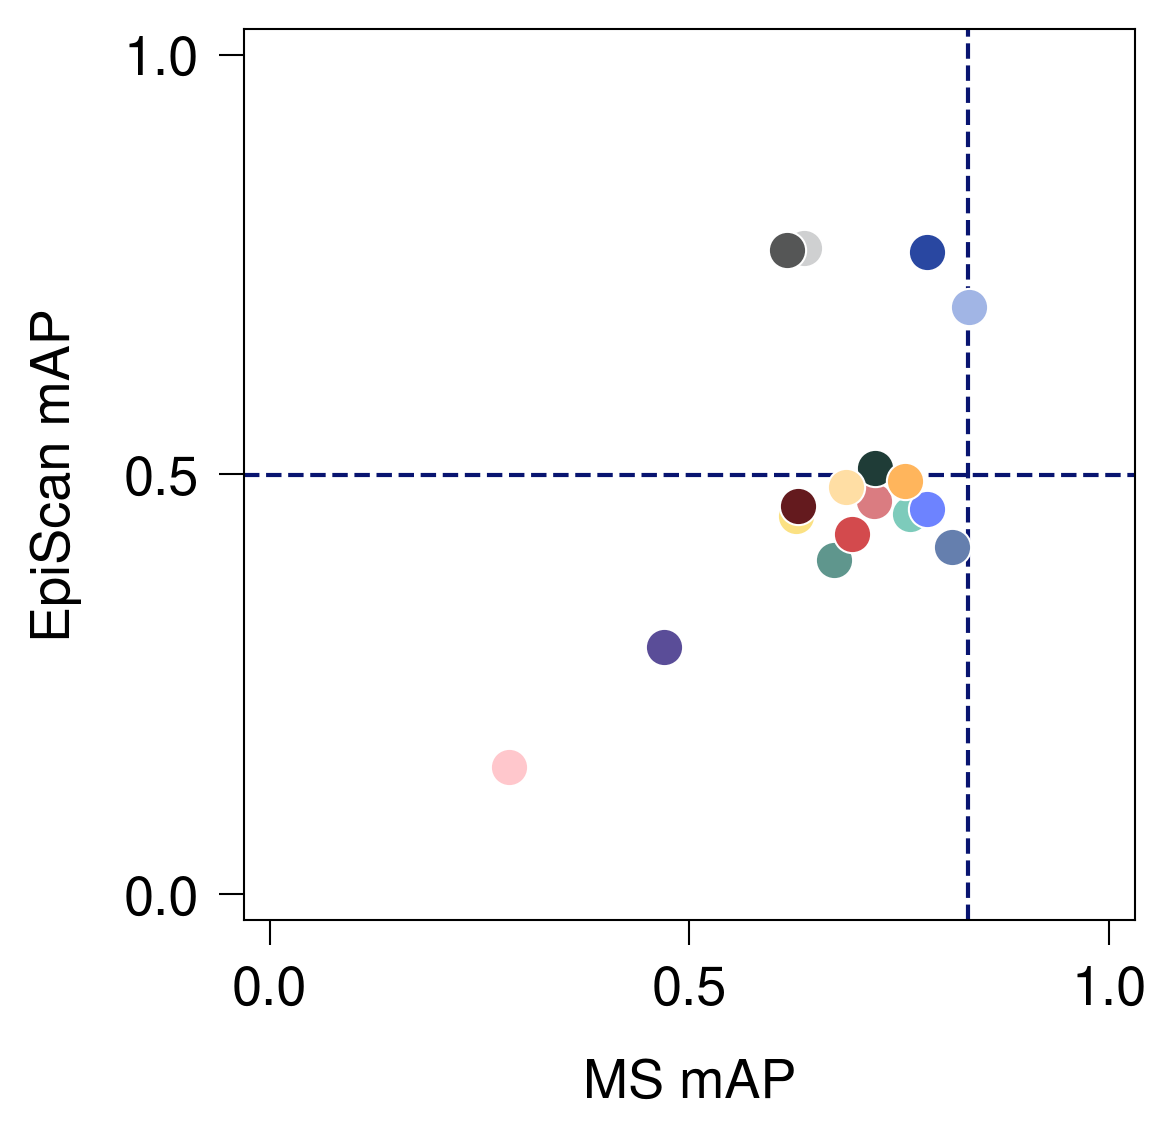

In [ ]:
# r9/rt pos versus r9 neg (easy background)
plot_single_metric_comparison_precomputed_y(
    ms_test_data[ms_test_data.allele.isin(['B5701', 'A0301', 'B0801', 'A0201'])].query("seq_len == 9"),
    r9rt_pos_r9_neg_mixed_map_df,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_e_epi_cl_r9rt_pos_r9_neg_mixed_map_vs_ms_map_scatterplot",
    **plotting_params,
)

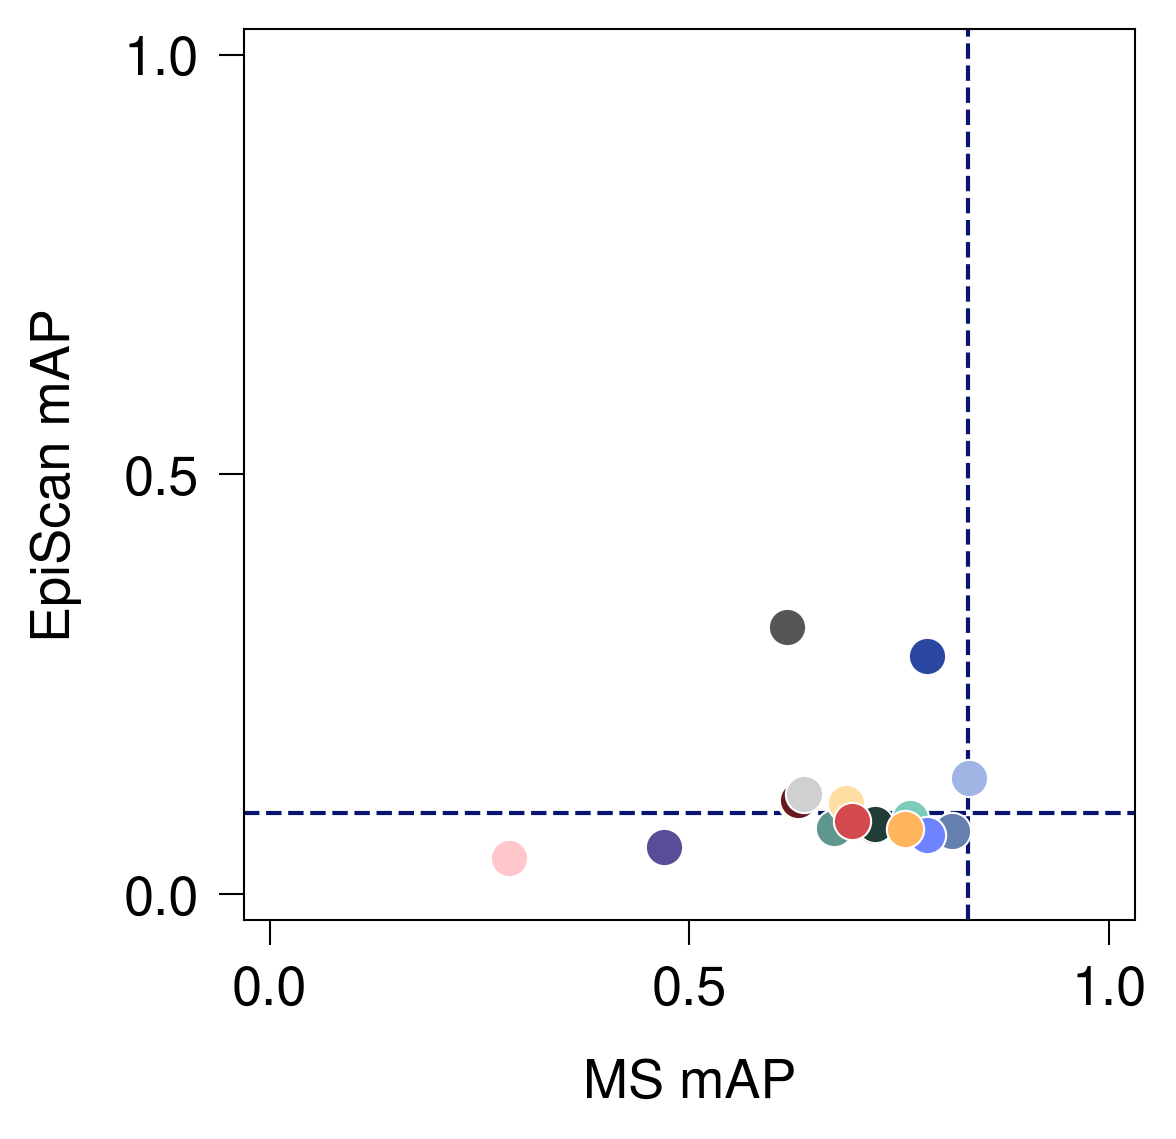

In [ ]:
# r9/rt pos versus r9/rt neg (hard background)
plot_single_metric_comparison_precomputed_y(
    ms_test_data[ms_test_data.allele.isin(['B5701', 'A0301', 'B0801', 'A0201'])].query("seq_len == 9"),
    r9rt_pos_r9rt_neg_mixed_map_df,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_e_epi_cl_r9rt_pos_r9rt_neg_mixed_map_vs_ms_map_scatterplot",
    **plotting_params,
)

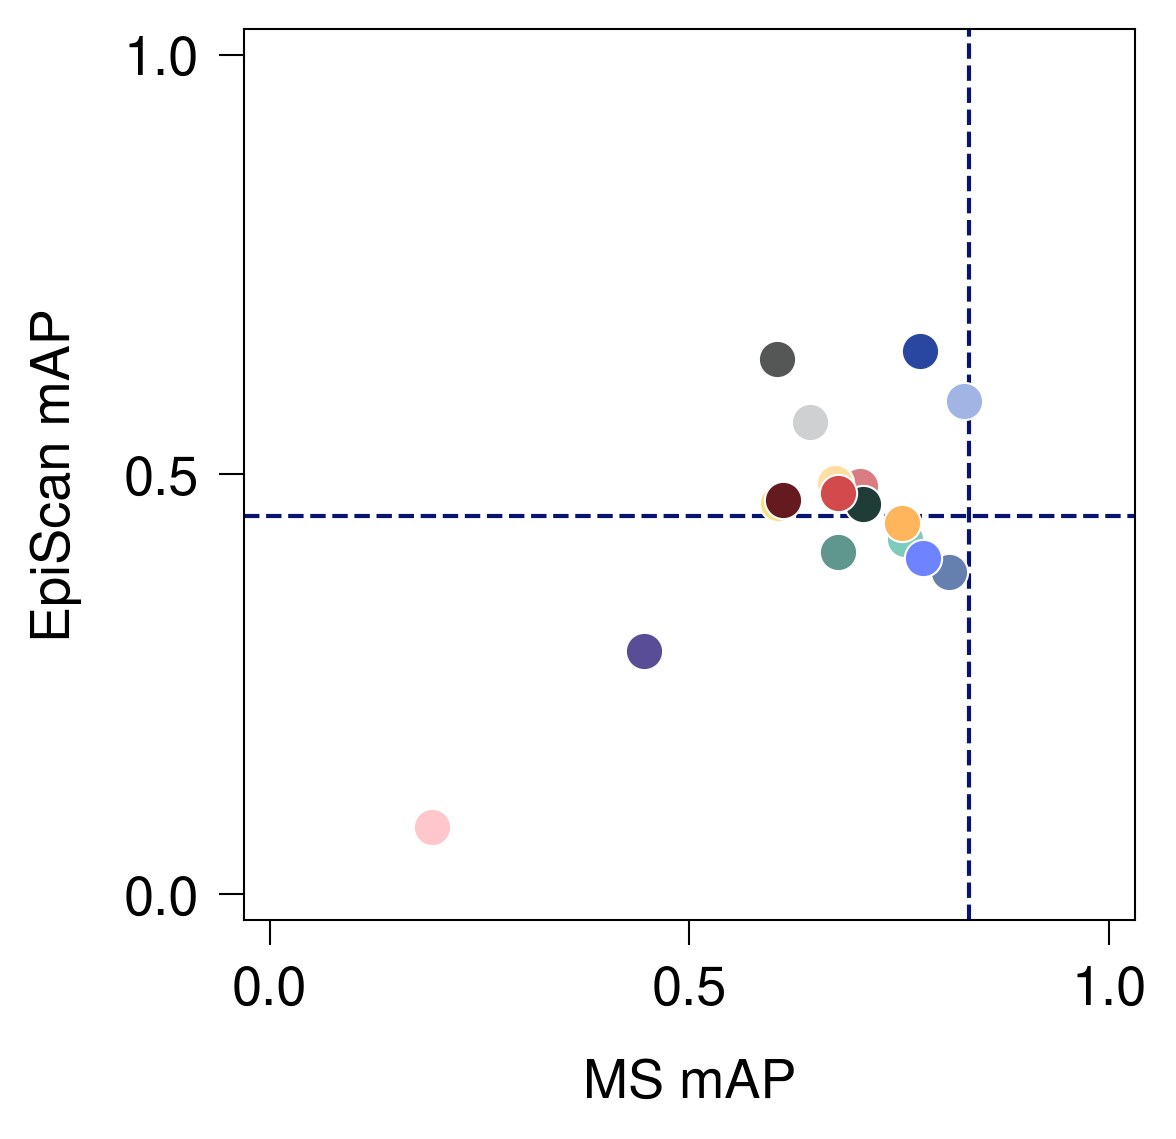

In [ ]:
# episcan sars-cov-2 set
plot_single_metric_comparison_precomputed_y(
    ms_cov_matched_allele_length,
    sd3_mixed_map_df,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_e_epi_cl_sd3_cov_matched_allele_mixed_map_vs_ms_map_scatterplot",
    **plotting_params,
)


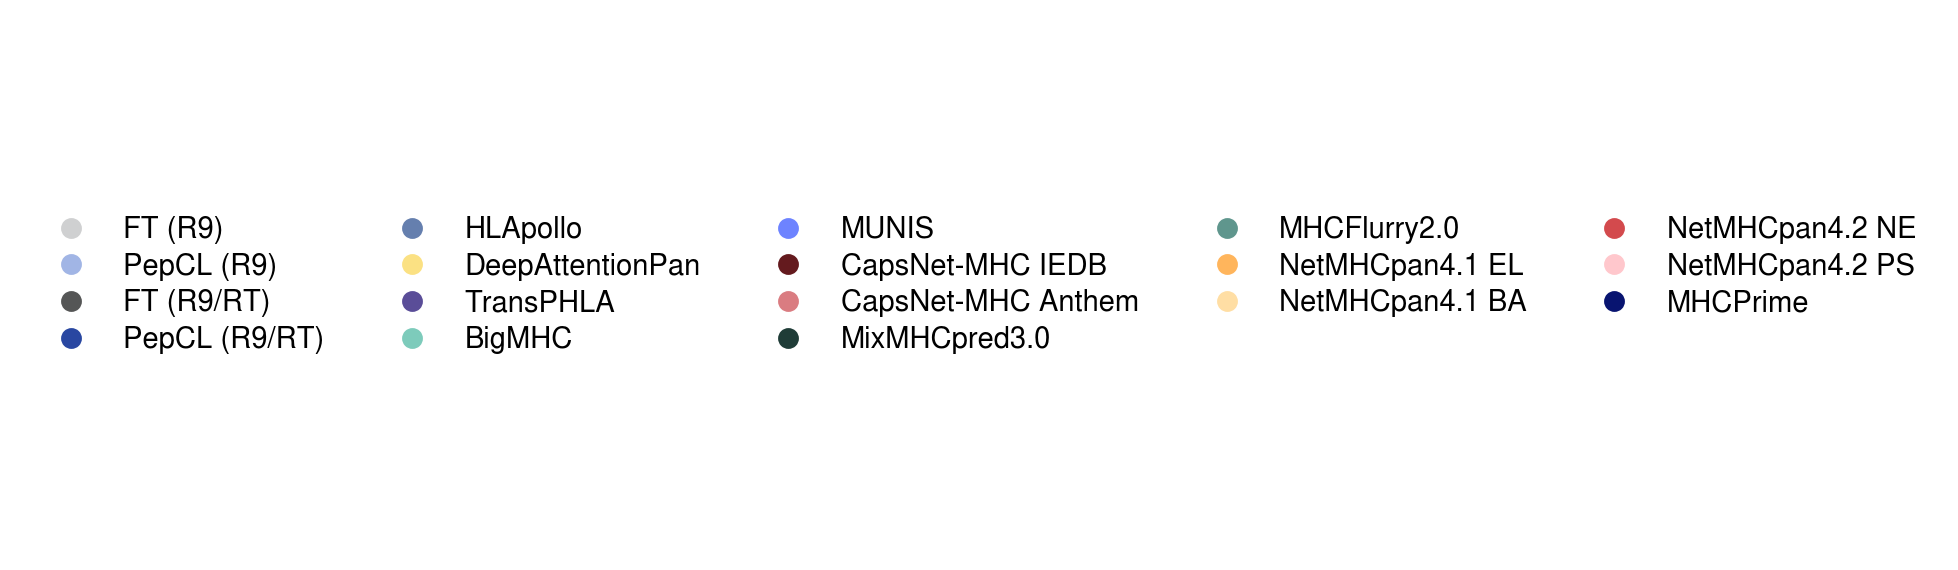

In [ ]:
# legend adjusted in illustrator
legend_dict={
    "FT (R9)": "#cfd0d1",
    "PepCL (R9)": "#a1b5e5",
    "FT (R9/RT)": "#555656",
    "PepCL (R9/RT)": "#2947a1",

    "HLApollo": "#657fae",
    "DeepAttentionPan": "#FBE183", 
    "TransPHLA": "#5A4D98",
    "BigMHC": "#7DCBBB", 
    "MUNIS": "#6D83FF",
    "CapsNet-MHC IEDB": "#641A1E", 
    "CapsNet-MHC Anthem": "#DA7C81", 
    "MixMHCpred3.0":"#1F3C37", 
    "MHCFlurry2.0":"#5F968D", 
    "NetMHCpan4.1 EL": "#ffb55c",
    "NetMHCpan4.1 BA": "#ffdea4",
    "NetMHCpan4.2 NE":"#d34a4d", 
    "NetMHCpan4.2 PS":"#ffc7cc", 
    # "MS+ LO": "#a4a4a4",
    "MHCPrime": "#081470", # move to end -> convert to dashed line

}

plot_legend(
    legend_dict,
    ncol=5, 
    figsize=(6, 2), # display size
    # figsize=(25, 6), # download size
    dpi=300, 
    fontsize=7, 
    marker='o', 
    marker_size=4,
    default_font='Nimbus Sans', 
    row_spacing=0.3,
    save_path=None
    # save_path=f"{central_figure_dir}/fig4_e_legend",

)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    r9rt_pos_r9_neg_mixed_map_df.to_csv(f"{associated_data_dir}/r9rt_pos_r9_neg_mixed_map_df.csv")
    r9rt_pos_r9rt_neg_mixed_map_df.to_csv(f"{associated_data_dir}/r9rt_pos_r9rt_neg_mixed_map_df.csv")
    ms_allele_ap_matrix_for_episcan_r9rt.to_csv(f"{associated_data_dir}/ms_allele_ap_matrix_for_episcan_r9rt.csv")
    sd3_mixed_map_df.to_csv(f"{associated_data_dir}/sd3_mixed_map_df.csv")
    ms_allele_ap_matrix_for_episcan_cov.to_csv(f"{associated_data_dir}/ms_allele_ap_matrix_for_episcan_cov.csv")

### Fig. 4f: BA updating results

In [ ]:
# ms/ba test sets
datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets"
ms_test_data=pd.read_csv(f"{datasets_dir}/ms_test_data.csv", index_col=0)

ba_train_test_dir = DATA_DIR / "Training_Datasets" / "Processed" / "BA"
test_df_ba_for_updating=pd.read_csv(f"{ba_train_test_dir}/test_df_ba_for_updating.csv", index_col=0)

In [ ]:
# match allele length distribuction for ms data
# get seq len
test_df_ba_for_updating["seq_len"]=test_df_ba_for_updating.seq.str.replace("$", "").apply(len)
ms_test_data["seq_len"]=ms_test_data.seq.str.replace("$", "").apply(len)

ms_test_data_allele_length_matched=filter_to_shared_pairs(ms_test_data, test_df_ba_for_updating, allele_col='allele', seq_len_col='seq_len')

print_data_stats(ms_test_data_allele_length_matched)

Total: 1,361,400
Pos: 13,614 | 1.00%
Neg: 1,347,786 | 99.00%
N alleles: 51


In [ ]:
# ap per allele
# get ap matrix
score_cols=["mhcprime", "ba_ft_con", "ba_pepcl_con"]

# ms test set (matched allele-length distribution)
ms_allele_ap_df=compute_ap_matrix_optimized(ms_test_data_allele_length_matched, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)

# ba test set (spearman correlation)
ba_allele_spearman_df=compute_spearman_matrix_optimized(test_df_ba_for_updating, score_cols, reference_col="ba_value", allele_col='allele', disable_tqdm=True)

{'MHCPrime': ['mhcprime'], 'FT': ['ba_ft_con'], 'PepCL': ['ba_pepcl_con']}


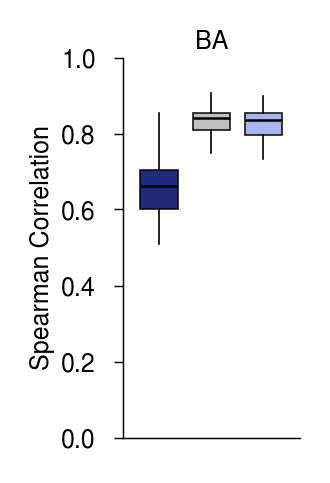

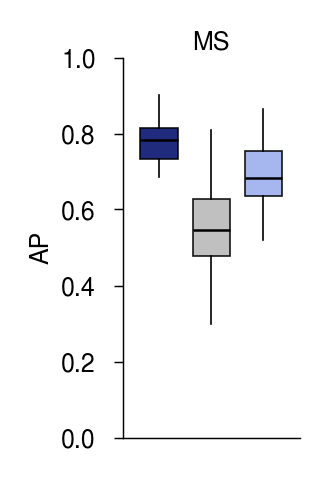

In [ ]:
# plot all together
score_cols=["mhcprime", "ba_ft_con", "ba_pepcl_con"]

model_groups = {
    'MHCPrime': ["mhcprime"],
    'FT': ["ba_ft_con"],
    'PepCL': ["ba_pepcl_con"],
}

x_ticks = ['']
print(model_groups)

colors = {
    'MHCPrime': '#081470',
    'FT': '#bababa',
    'PepCL': '#9bb0ed',
}

plot_params = {
    'title': '',
    'title_y': 1.04,
    'title_bbox': None,
    # 'title_fontsize': 7,
    'title_fontsize': 6,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AP',
    # 'xlabel_fontsize': 7,
    # 'ylabel_fontsize': 7,
    'xlabel_fontsize': 6,
    'ylabel_fontsize': 6,
    'figsize': (1.20, 1.65),
    'dpi': 300,
    'legend_fontsize': 6,
    'legend_cols': 3,
    'legend_handle_size': 0.7,
    'axis_linewidth': 0.35,
    # 'axis_linewidth': 0.30,
    # 'axis_linewidth': 0.25,
    'tick_length': 2.2,
    'xlabel_pad': 1,
    'ylabel_pad': 1.5,
    'xtick_labelsize': 5.5,
    'ytick_labelsize': 6,
}

plotting_parameters = dict(
    model_col='model_name',
    score_col='metric',
    model_groups=model_groups,
    x_ticks=[''],
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 1.0),
    grid_alpha=0,
    default_font='Nimbus Sans',
    mode='box',
    bar_width=0.32,
    bar_spacing=0.08,
    group_spacing=0.10,
    x_margin=0.12,
    bar_outline_color='black',
    box_median_width=0.60,
    # bar_outline_width=0.35,
    # box_whisker_width=0.30,
    bar_outline_width=0.40,
    box_whisker_width=0.40,
    box_flier_size=0,
    legend_mode=None,
    xtick_rotation=0,

    pval_df=None,
    pval_fontsize=4,
    pval_linewidth=0.35,
    pval_color='black',
    pval_bar_offset=0.035,
    pval_bar_spacing=0.06,
    pval_text_offset=0.004,
    pval_star_text_offset=-0.01,
    pval_ns_text_offset=0.004,
)

plot_params["ylabel"] = "Spearman Correlation"
plot_params["title"] = "BA"
plotting_parameters["plot_params"]=plot_params
_=plot_model_performance_bars_or_box_v2(
    df=ba_allele_spearman_df,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_f_ba_continuous_value_updating_per_allele_spearman_correlation_boxplots",
    **plotting_parameters
)


plot_params["ylabel"] = "AP"
plot_params["title"] = "MS"
plotting_parameters["plot_params"]=plot_params
_=plot_model_performance_bars_or_box_v2(
    df=ms_allele_ap_df,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_f_ms for_ba_continuous_value_updating_per_allele_ap_boxplots",
    **plotting_parameters
)



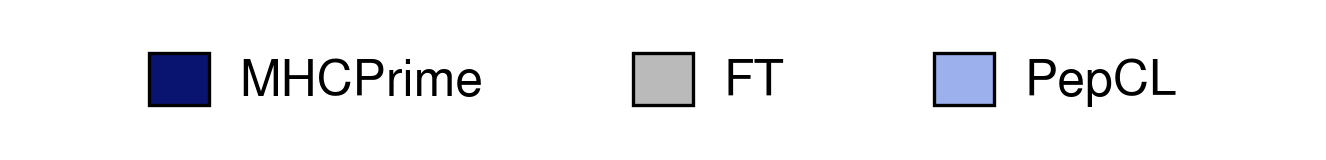

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'MHCPrime': '#081470',
        'FT': '#bababa',
        'PepCL': '#9bb0ed',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_f_legend",
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    ba_allele_spearman_df.to_csv(f"{associated_data_dir}/ba_allele_spearman_df.csv")
    ms_allele_ap_df.to_csv(f"{associated_data_dir}/ms_for_ba_allele_ap_df.csv")

### Fig. 4g: ESCAPE-seq reported neoantigen recovery

In [ ]:
# get data

# escape seq
escape_seq_datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "ESCAPE_seq"
escapeseq_reported_neoantigens=pd.read_csv(f"{escape_seq_datasets_dir}/escapeseq_reported_neoantigens.csv", index_col=0)
escapeseq_reported_neoantigens_expanded=pd.read_csv(f"{escape_seq_datasets_dir}/escapeseq_reported_neoantigens_expanded.csv", index_col=0)

# process
escapeseq_reported_neoantigens=full_process_data(escapeseq_reported_neoantigens, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
escapeseq_reported_neoantigens_expanded=full_process_data(escapeseq_reported_neoantigens_expanded, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)

In [ ]:
# get nmp41 escape seq predictions
escape_seq_all_data_nmp41=pd.read_csv(f"{escape_seq_datasets_dir}/escape_seq_all_data_nmp41.csv")
escape_seq_all_data_nmp41=create_seq_allele_column(escape_seq_all_data_nmp41)

# process
escape_seq_all_data_nmp41_processed=full_process_data(escape_seq_all_data_nmp41, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
escape_seq_all_data_nmp41_processed=create_seq_allele_column(escape_seq_all_data_nmp41_processed)
escape_seq_all_data_nmp41_processed["method_group"]='nonMS'
print_data_stats(escape_seq_all_data_nmp41_processed)

# map to neoants
seq_allele_to_score=dict(zip(escape_seq_all_data_nmp41_processed.seq_allele, escape_seq_all_data_nmp41_processed.BA_Rank))
escapeseq_reported_neoantigens_expanded["BA_Rank"]=escapeseq_reported_neoantigens_expanded.seq_allele.map(seq_allele_to_score)

seq_allele_to_score=dict(zip(escape_seq_all_data_nmp41_processed.seq_allele, escape_seq_all_data_nmp41_processed.EL_Rank))
escapeseq_reported_neoantigens_expanded["EL_Rank"]=escapeseq_reported_neoantigens_expanded.seq_allele.map(seq_allele_to_score)

Total: 87,267
Pos: 9,464 | 10.84%
Neg: 77,803 | 89.16%
N alleles: 50


In [ ]:
# exclude top neoantigens
escapeseq_reported_neoantigens=create_seq_allele_column(escapeseq_reported_neoantigens)
escapeseq_reported_neoantigens_expanded=create_seq_allele_column(escapeseq_reported_neoantigens_expanded)
escapeseq_reported_neoantigens_expanded_remaining=escapeseq_reported_neoantigens_expanded[~escapeseq_reported_neoantigens_expanded.seq_allele.isin(escapeseq_reported_neoantigens.seq_allele.unique())]
print(escapeseq_reported_neoantigens_expanded_remaining.shape)

# for the top neoantigens
escapeseq_reported_neoantigens=create_seq_allele_column(escapeseq_reported_neoantigens)
escapeseq_reported_neoantigens_expanded=create_seq_allele_column(escapeseq_reported_neoantigens_expanded)
escapeseq_reported_neoantigens_expanded_top=escapeseq_reported_neoantigens_expanded[escapeseq_reported_neoantigens_expanded.seq_allele.isin(escapeseq_reported_neoantigens.seq_allele.unique())]
print(escapeseq_reported_neoantigens_expanded_top.shape)

(204, 41)
(21, 41)


In [ ]:
# get recovery
score_cols=["mhcprime", "escape_seq_neoant_ft_con", "escape_seq_neoant_pepcl_con"]
score_cols_external=["EL_Rank", "BA_Rank"]

escapeseq_top_neoantigens_recovery=compute_recovery(escapeseq_reported_neoantigens_expanded_top, score_cols, score_cols_external, threshold=98)
escapeseq_remaining_neoantigens_recovery=compute_recovery(escapeseq_reported_neoantigens_expanded_remaining, score_cols, score_cols_external, threshold=98)

# adj col name
escapeseq_top_neoantigens_recovery.model_name=[f"{c}_top" for c in escapeseq_top_neoantigens_recovery.model_name]
escapeseq_remaining_neoantigens_recovery.model_name=[f"{c}_rem" for c in escapeseq_remaining_neoantigens_recovery.model_name]

# merge
escapeseq_neoantigens_recovery=pd.concat([escapeseq_top_neoantigens_recovery, escapeseq_remaining_neoantigens_recovery])

{'mhcprime': ['mhcprime_top', 'mhcprime_rem'], 'escape_seq_neoant_ft_con': ['escape_seq_neoant_ft_con_top', 'escape_seq_neoant_ft_con_rem'], 'escape_seq_neoant_pepcl_con': ['escape_seq_neoant_pepcl_con_top', 'escape_seq_neoant_pepcl_con_rem'], 'EL_Rank': ['EL_Rank_top', 'EL_Rank_rem'], 'BA_Rank': ['BA_Rank_top', 'BA_Rank_rem']}


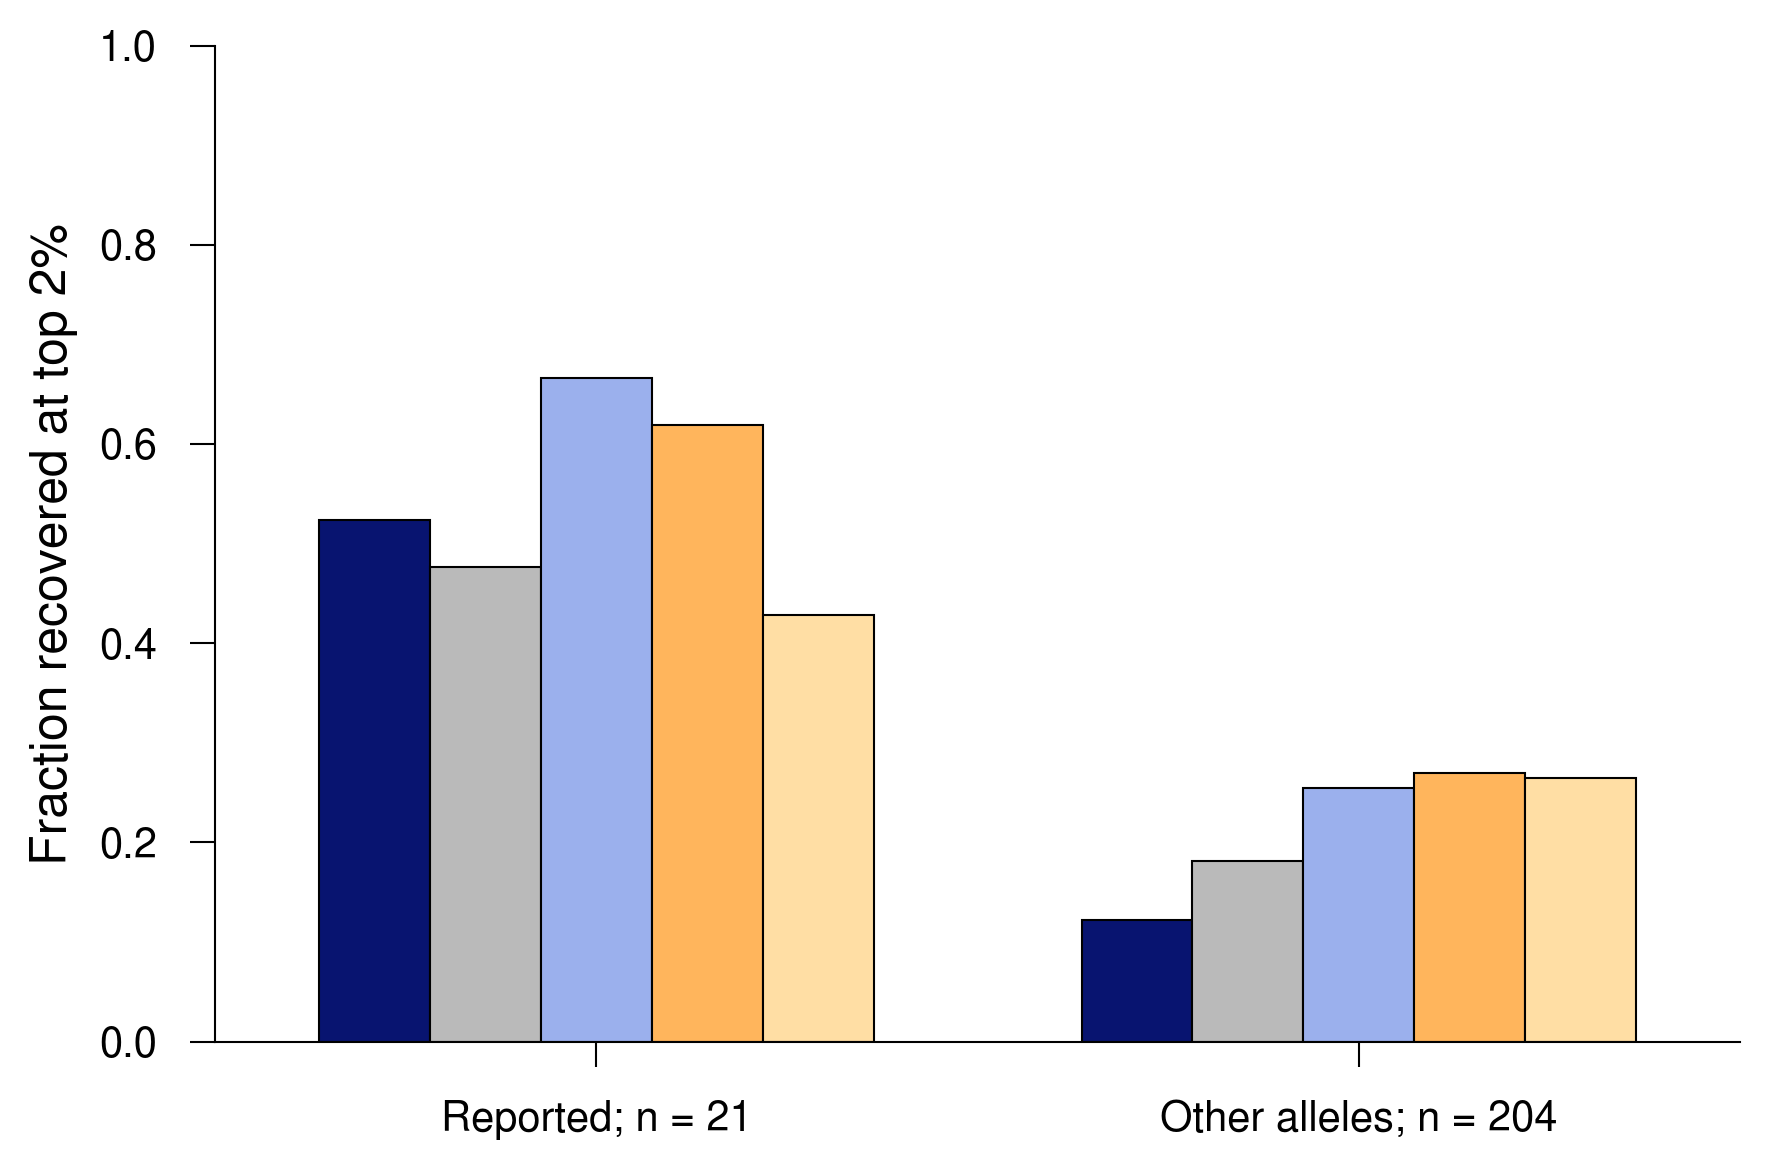

In [ ]:
# plot line plot
model_groups = {m: [f"{m}_top", f"{m}_rem"] for m in score_cols + score_cols_external}
print(model_groups)
# x_ticks = ["(E-score > 3.8; n = 21)", "(E-score > 3.5; n = 204)"]
x_ticks = ["Reported; n = 21", "Other alleles; n = 204"]
colors = {
    'mhcprime': '#081470',
    'escape_seq_neoant_ft_con': '#bababa',
    'escape_seq_neoant_pepcl_con': '#9bb0ed',
    'EL_Rank': '#ffb55c',
    'BA_Rank': '#ffdea4'
}
plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'Fraction recovered at top 2%',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (6, 4),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 6.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10
}


_=plot_model_performance_bars_or_box_v2(
    df=escapeseq_neoantigens_recovery, # for the barplot
    model_col='model_name',
    score_col='recovered',
    model_groups=model_groups,
    x_ticks=x_ticks,
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 1.0),
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    bar_width=0.8,
    group_spacing=1.5,
    bar_spacing=0.0,
    bar_outline_color='black',
    bar_outline_width=0.5,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style=':',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=12,
    hline_text_offset=0.005,
    hline_text_x_offset=-0.035,
    hline_in_legend=True,
    legend_mode=None,
    mode='bar',
    box_flier_size=2,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_g_top_and_remaining_neoantigen_recovery_grouped_barplot_con_models"
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    escapeseq_neoantigens_recovery.to_csv(f"{associated_data_dir}/escapeseq_neoantigens_recovery.csv")

### Fig. 4h: ESCAPE-seq differential mutation calling

In [ ]:
# get data

# get nmp41 escape seq predictions
escape_seq_datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "ESCAPE_seq"
escape_seq_all_data_nmp41=pd.read_csv(f"{escape_seq_datasets_dir}/escape_seq_all_data_nmp41.csv")
escape_seq_all_data_nmp41=create_seq_allele_column(escape_seq_all_data_nmp41)

# process
escape_seq_all_data_nmp41_processed=full_process_data(escape_seq_all_data_nmp41, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
escape_seq_all_data_nmp41_processed=create_seq_allele_column(escape_seq_all_data_nmp41_processed)
escape_seq_all_data_nmp41_processed["method_group"]='nonMS'
print_data_stats(escape_seq_all_data_nmp41_processed)

Total: 87,267
Pos: 9,464 | 10.84%
Neg: 77,803 | 89.16%
N alleles: 50


In [ ]:
%%time
# process gene holdout results
central_ft_dir=f"{DATA_DIR}/ESCAPE_seq_gene_holdout_experiment"
output_df_dir="inference_dfs_updated"

genes_to_run=['JAK2', 'MAX', 'MPL', 'MED12', 'TP53', 'SRSF2', 'NOTCH2', 'EZH2', 'AKT1', 'IDH1', 'ATM', 'MYD88', 'EGFR', 'FGFR3', 'PTEN', 'SF3B1', 'CREBBP', 'MYC', 'FBXW7', 'BRAF', 'RET', 'SMAD4', 'ERBB2', 'GNAS', 'DNMT3A', 'ALK', 'KIAA1549', 'EWSR1']

# add genes from gene groups
gene_groups={
    "KRAS": ["KRAS", "KRAS-NRAS", "KRAS-KRAS-NRAS-NRAS-HRAS-HRAS", "KRAS-HRAS", "KRAS-NRAS-HRAS", "HRAS", "NRAS-HRAS"], 
    "FLT3": ["FLT3", "KIT", "PDGFRA", "FLT3-KIT-PDGFRA", "FLT3-PDGFRA"],
    "IDH2": ["IDH2", "IDH2-IDH2"],
    "PIK3CA": ["PIK3CA", "PIK3CA-PIK3CA"],
    "CTNNB1": ["CTNNB1", "CTNNB1-CTNNB1"],
}

genes_to_run+=list(gene_groups.keys())

allele_ap_matrix_wt_neg_mut_pos=pd.DataFrame()
allele_ap_matrix_wt_pos_mut_neg=pd.DataFrame()

full_spearmans=pd.DataFrame()
wt_spearmans=pd.DataFrame()
mut_spearmans=pd.DataFrame()
wt_mut_gene_diff_noX_spearmans=pd.DataFrame()

for gene in tqdm(genes_to_run):

    mut_wt_df_gene=pd.read_csv(f"{central_ft_dir}/{output_df_dir}/mut_wt_df_gene_{gene}.csv")

    mut_wt_df_gene["name_allele"]=[f"{n}_{a}" for n, a in zip(mut_wt_df_gene.name2, mut_wt_df_gene.allele)]

    mut_wt_df_gene=create_seq_allele_column(mut_wt_df_gene)

    # map el and ba scores
    external_models=["EL_score", "BA_score"]
    for em in external_models:
        seq_allele_to_score=dict(zip(escape_seq_all_data_nmp41_processed.seq_allele, escape_seq_all_data_nmp41_processed[em]))
        mut_wt_df_gene[em]=mut_wt_df_gene.seq_allele.map(seq_allele_to_score)

    score_cols=["model_base", "model_ft", "model_pepcl"]
    
    # add external models
    score_cols+=["EL_score", "BA_score"]

    wt_mut_gene_diff_noX=pair_wt_mut_and_diff_with_quadrants_v2(
        df=filter_sequences_without_x(mut_wt_df_gene),
        score_cols=score_cols + ["escore"],
        # id_col="name2",
        id_col="name_allele",
        mut_type_col = "mut_type",
        wt_value = "wt",
        mut_value = "mut",
        allele_col = "allele",
        mutation_col = "mutation",
        seq_col = "seq",
        label_col = "label",
        quadrant_col = "wt_mut_quadrant",
        seed = 42,
        dup_mode = "pair_enumeration",

    )

    wt_mut_gene_diff_noX=add_quadrant_binary_label(
        df=wt_mut_gene_diff_noX,
        quadrant_col="wt_mut_quadrant",
        quadrant_name="WT-/MUT+",
        out_label_col = "quadrant_label",
    )
    wt_mut_gene_diff_noX_negated=wt_mut_gene_diff_noX.copy()

    wt_mut_gene_diff_noX_negated=add_quadrant_binary_label(
        df=wt_mut_gene_diff_noX_negated,
        quadrant_col="wt_mut_quadrant",
        quadrant_name="WT+/MUT-",
        out_label_col = "quadrant_label",
    )

    for score_col in score_cols + ["escore"]:
        wt_mut_gene_diff_noX_negated[score_col]=-wt_mut_gene_diff_noX_negated[score_col]

    wt_mut_gene_diff_noX=compute_hamming(wt_mut_gene_diff_noX, "seq_wt", "seq_mut", "hamming_dist")
    wt_mut_gene_diff_noX=wt_mut_gene_diff_noX.query("hamming_dist >= 1")

    wt_mut_gene_diff_noX["all"]=1
    allele_ap_matrix=compute_ap_matrix_optimized(wt_mut_gene_diff_noX.query("allele != 'A6801'"), score_cols + ["escore"], label_col='quadrant_label', allele_col='all', disable_tqdm=True) # use reverse_rank_score_cols instead of rank_score_cols

    allele_ap_matrix.index=[gene]
    allele_ap_matrix_wt_neg_mut_pos=pd.concat([allele_ap_matrix_wt_neg_mut_pos, allele_ap_matrix])

    wt_mut_gene_diff_noX_negated=compute_hamming(wt_mut_gene_diff_noX_negated, "seq_wt", "seq_mut", "hamming_dist")
    wt_mut_gene_diff_noX_negated=wt_mut_gene_diff_noX_negated.query("hamming_dist >= 1")

    wt_mut_gene_diff_noX_negated["all"]=1
    allele_ap_matrix=compute_ap_matrix_optimized(wt_mut_gene_diff_noX_negated.query("allele != 'A6801'"), score_cols + ["escore"], label_col='quadrant_label', allele_col='all', disable_tqdm=True) # use reverse_rank_score_cols instead of rank_score_cols

    allele_ap_matrix.index=[gene]
    allele_ap_matrix_wt_pos_mut_neg=pd.concat([allele_ap_matrix_wt_pos_mut_neg, allele_ap_matrix])

    base_col="escore"
    full_spearman_df=spearman_vs_base(filter_sequences_without_x(mut_wt_df_gene).query("allele != 'A6801'"), score_cols, base_col, index_name=gene)
    wt_spearman_df=spearman_vs_base(filter_sequences_without_x(mut_wt_df_gene).query("allele != 'A6801'").query("mut_type == 'wt'"), score_cols, base_col, index_name=gene)
    mut_spearman_df=spearman_vs_base(filter_sequences_without_x(mut_wt_df_gene).query("allele != 'A6801'").query("mut_type == 'mut'"), score_cols, base_col, index_name=gene)
    wt_mut_gene_diff_noX_spearman_df=spearman_vs_base(wt_mut_gene_diff_noX.query("allele != 'A6801'"), score_cols, base_col, index_name=gene)

    full_spearmans=pd.concat([full_spearmans, full_spearman_df])
    wt_spearmans=pd.concat([wt_spearmans, wt_spearman_df])
    mut_spearmans=pd.concat([mut_spearmans, mut_spearman_df])
    wt_mut_gene_diff_noX_spearmans=pd.concat([wt_mut_gene_diff_noX_spearmans, wt_mut_gene_diff_noX_spearman_df])


100%|██████████| 33/33 [00:07<00:00,  4.31it/s]

CPU times: user 7.55 s, sys: 138 ms, total: 7.68 s
Wall time: 7.66 s


In [ ]:
# compute p-values
allele_ap_matrix_wt_neg_mut_pos_pval_df=compute_pairwise_pvalues_general(allele_ap_matrix_wt_neg_mut_pos)
display(allele_ap_matrix_wt_neg_mut_pos_pval_df)
display(pval_to_stars(allele_ap_matrix_wt_neg_mut_pos_pval_df))

allele_ap_matrix_wt_pos_mut_neg_pval_df=compute_pairwise_pvalues_general(allele_ap_matrix_wt_pos_mut_neg)
display(allele_ap_matrix_wt_pos_mut_neg_pval_df)
display(pval_to_stars(allele_ap_matrix_wt_pos_mut_neg_pval_df))

,model_base,model_ft,model_pepcl,EL_score,BA_score,escore
model_base,1.000000e+00,3.156269e-04,2.328306e-10,1.002802e-06,6.984919e-10,2.328306e-10
model_ft,3.156269e-04,1.000000e+00,3.724645e-04,1.167764e-01,7.832363e-03,2.328306e-10
model_pepcl,2.328306e-10,3.724645e-04,1.000000e+00,1.297176e-02,4.263604e-01,2.328306e-10
EL_score,1.002802e-06,1.167764e-01,1.297176e-02,1.000000e+00,1.472702e-03,2.328306e-10
BA_score,6.984919e-10,7.832363e-03,4.263604e-01,1.472702e-03,1.000000e+00,2.328306e-10
escore,2.328306e-10,2.328306e-10,2.328306e-10,2.328306e-10,2.328306e-10,1.000000e+00


,model_base,model_ft,model_pepcl,EL_score,BA_score,escore
model_base,ns,***,****,****,****,****
model_ft,***,ns,***,ns,**,****
model_pepcl,****,***,ns,*,ns,****
EL_score,****,ns,*,ns,**,****
BA_score,****,**,ns,**,ns,****
escore,****,****,****,****,****,ns


,model_base,model_ft,model_pepcl,EL_score,BA_score,escore
model_base,1.000000e+00,1.768082e-01,4.048925e-07,5.568552e-04,2.935994e-07,2.328306e-10
model_ft,1.768082e-01,1.000000e+00,1.099177e-04,2.276420e-01,1.276292e-03,2.328306e-10
model_pepcl,4.048925e-07,1.099177e-04,1.000000e+00,1.695537e-03,9.578276e-01,2.328306e-10
EL_score,5.568552e-04,2.276420e-01,1.695537e-03,1.000000e+00,1.025265e-03,2.328306e-10
BA_score,2.935994e-07,1.276292e-03,9.578276e-01,1.025265e-03,1.000000e+00,2.328306e-10
escore,2.328306e-10,2.328306e-10,2.328306e-10,2.328306e-10,2.328306e-10,1.000000e+00


,model_base,model_ft,model_pepcl,EL_score,BA_score,escore
model_base,ns,ns,****,***,****,****
model_ft,ns,ns,***,ns,**,****
model_pepcl,****,***,ns,**,ns,****
EL_score,***,ns,**,ns,**,****
BA_score,****,**,ns,**,ns,****
escore,****,****,****,****,****,ns


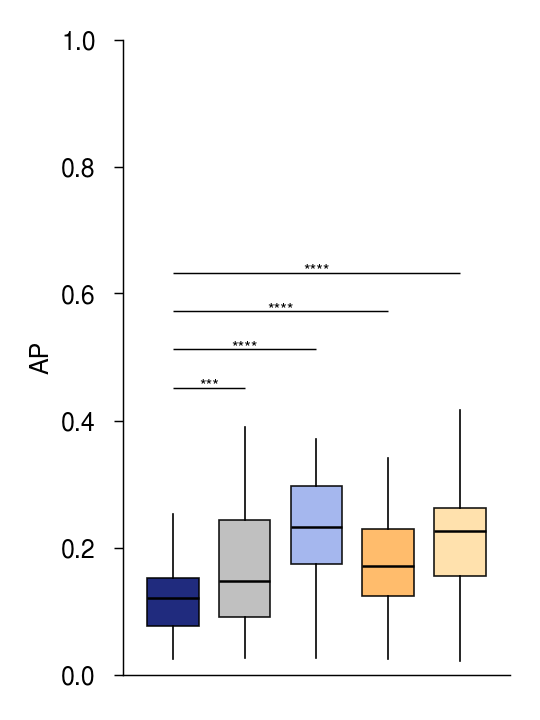

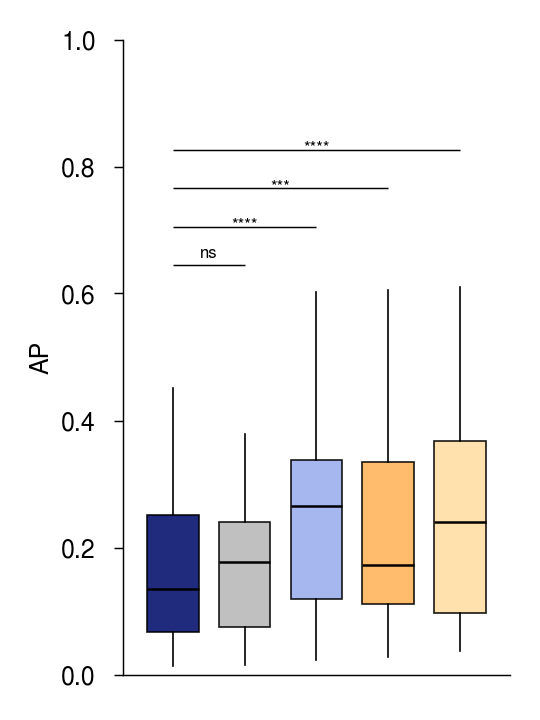

In [ ]:
# plot grouped boxplots for gain and escape mutations
score_cols = [
    "model_base",
    "model_ft",
    "model_pepcl",
    "EL_score",
    "BA_score",
]

model_groups = {
    'Base': ['model_base'],
    'FT': ['model_ft'],
    'PepCL': ['model_pepcl'],
    'NMP41_EL': ['EL_score'],
    'NMP41_BA': ['BA_score'],
}

x_ticks = ['']

colors = {
    'Base': '#081470',
    'FT': '#bababa',
    'PepCL': '#9bb0ed',
    'NMP41_EL': "#ffb55c",
    'NMP41_BA': "#ffdea4",
}

plot_params = {
    'title': '',
    'title_y': 1.04,
    'title_bbox': None,
    'title_fontsize': 6,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AP',
    'xlabel_fontsize': 6,
    'ylabel_fontsize': 6,
    'figsize': (1.90, 2.5),
    'dpi': 300,
    'legend_fontsize': 6,
    'legend_cols': 5,
    'legend_handle_size': 0.7,
    'axis_linewidth': 0.35,
    'tick_length': 2.2,
    'xlabel_pad': 1,
    'ylabel_pad': 1.5,
    'xtick_labelsize': 5.5,
    'ytick_labelsize': 6,
}

plotting_parameters = dict(
    model_col='model_name',
    score_col='metric',
    model_groups=model_groups,
    x_ticks=x_ticks,
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 1.0),
    grid_alpha=0,
    default_font='Nimbus Sans',
    mode='box',
    bar_width=0.32,
    bar_spacing=0.08,
    group_spacing=0.10,
    x_margin=0.12,
    bar_outline_color='black',
    box_median_width=0.60,
    bar_outline_width=0.40,
    box_whisker_width=0.40,
    box_flier_size=0,
    legend_mode=None,
    xtick_rotation=0,
    pval_df=None,
    pval_base_only=True,
    pval_base_col="model_base",
    pval_fontsize=4,
    pval_linewidth=0.35,
    pval_color='black',
    pval_bar_offset=0.035,
    pval_bar_spacing=0.06,
    pval_text_offset=0.004,
    pval_star_text_offset=-0.01,
    pval_ns_text_offset=0.004,
)

plotting_parameters['pval_df']=allele_ap_matrix_wt_neg_mut_pos_pval_df
_=plot_model_performance_bars_or_box_v2(
    df=allele_ap_matrix_wt_neg_mut_pos,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_h_escapeseq_gain_muts_con_updating_boxplots",
    **plotting_parameters,
)

plotting_parameters['pval_df']=allele_ap_matrix_wt_pos_mut_neg_pval_df
_=plot_model_performance_bars_or_box_v2(
    df=allele_ap_matrix_wt_pos_mut_neg,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_h_escapeseq_escape_muts_con_updating_boxplots",
    **plotting_parameters,
)

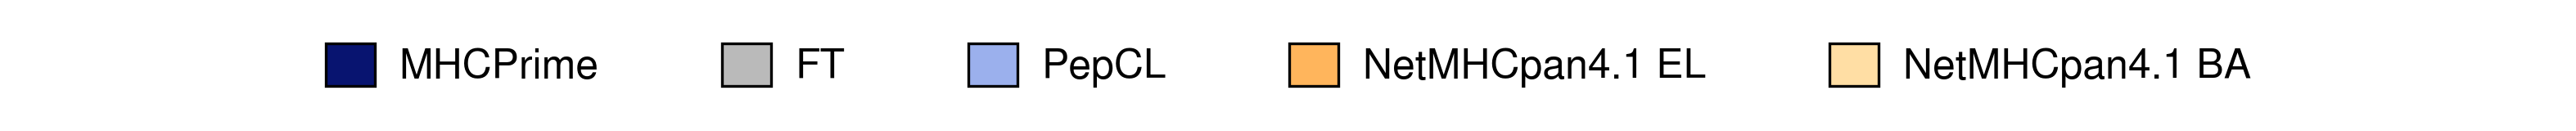

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'MHCPrime': '#081470',
        'FT': '#bababa',
        'PepCL': '#9bb0ed',
        'NetMHCpan4.1 EL': "#ffb55c",
        'NetMHCpan4.1 BA': "#ffdea4",
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/fig4_gh_legend",
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    allele_ap_matrix_wt_neg_mut_pos.to_csv(f"{associated_data_dir}/allele_ap_matrix_wt_neg_mut_pos.csv")
    allele_ap_matrix_wt_pos_mut_neg.to_csv(f"{associated_data_dir}/allele_ap_matrix_wt_pos_mut_neg.csv")

    allele_ap_matrix_wt_neg_mut_pos_pval_df.to_csv(f"{associated_data_dir}/allele_ap_matrix_wt_neg_mut_pos_pval_df.csv")
    allele_ap_matrix_wt_pos_mut_neg_pval_df.to_csv(f"{associated_data_dir}/allele_ap_matrix_wt_pos_mut_neg_pval_df.csv")
